### Stage 0.1 - Setup: imports, paths, module and checkpoint settings

In [2]:
# Libraries used in the data build and the feasibility check
import pandas as pd
import numpy as np
import os

# ---- Settings for CCC ----
MODULE = "CCC"                                    # module we are working on
PRES = ["2014B", "2014J"]                         # same presentations as the RQ1 merged file
FOCUS_ACT = "quiz"                                # the activity we look at most closely
RAW_DIR = r"C:\Users\Disha Sharma\Desktop\Paper_1\DATA"            # folder with the original OULAD CSVs
OUT_DIR = rf"C:\Users\Disha Sharma\Desktop\Paper_1\RQ4\{MODULE}"   # all outputs go here
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Checkpoints in days from the course start: 28 = end of week 4, 56 = end of week 8 ----
CUTOFFS = [28, 56]
EARLY_END, WIN_END = 28, 56      # early period = up to day 28; action window = days 29 to 56

### Stage 0.2 - Load the students: final result plus registration and unregistration dates

In [7]:
# studentInfo: final outcome for every student; studentRegistration: when they registered and left
info = pd.read_csv(os.path.join(RAW_DIR, "studentInfo.csv"))
reg = pd.read_csv(os.path.join(RAW_DIR, "studentRegistration.csv"))

# Keep only this module and its presentations
info = info[(info.code_module == MODULE) & (info.code_presentation.isin(PRES))]
reg = reg[(reg.code_module == MODULE) & (reg.code_presentation.isin(PRES))]

# One row per student (date_unregistration is empty for students who never left)
stu = info.merge(
    reg[['code_presentation', 'id_student', 'date_registration', 'date_unregistration']],
    on=['code_presentation', 'id_student'], how='left')

# Check: should match the RQ1 merged file (4,434 students)
print("students:", len(stu))
print(stu.final_result.value_counts().to_dict())

students: 4434
{'Withdrawn': 1975, 'Pass': 1180, 'Fail': 781, 'Distinction': 498}


### Stage 0.3 - Load the activity-type lookup (which page ids are quizzes, forums, etc.)

In [10]:
# vle.csv tells us the activity type of every course page
vle = pd.read_csv(os.path.join(RAW_DIR, "vle.csv"))
vle = vle[(vle.code_module == MODULE) & (vle.code_presentation.isin(PRES))][
    ['id_site', 'code_presentation', 'activity_type']]
print("pages:", len(vle), "| activity types:", sorted(vle.activity_type.unique()))

pages: 419 | activity types: ['forumng', 'homepage', 'oucollaborate', 'oucontent', 'page', 'quiz', 'resource', 'subpage', 'url']


### Stage 0.4 - Read the big click file in chunks and keep only this module (slowest cell, a few minutes)

In [13]:
# The click file is too big to load at once: read 500,000 rows at a time and keep only this module
parts = []                                      # reset so reruns do not duplicate rows
for i, chunk in enumerate(pd.read_csv(
        os.path.join(RAW_DIR, "studentVle.csv"),
        usecols=['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click'],
        chunksize=500_000)):
    chunk = chunk[(chunk.code_module == MODULE) & (chunk.code_presentation.isin(PRES))]
    if not chunk.empty:
        chunk = chunk.merge(vle, on=['id_site', 'code_presentation'], how='left')   # add the activity type
        parts.append(chunk[['code_presentation', 'id_student', 'activity_type', 'date', 'sum_click']])
    if i % 5 == 0:
        print("chunks read:", i + 1)       # progress

clicks = pd.concat(parts, ignore_index=True)
# 'date' = day of the click counted from the start (negative = before the start)
print("click rows:", len(clicks), "| date range:", clicks.date.min(), "to", clicks.date.max())
print("clicks with no activity type (should be about 0):", int(clicks.activity_type.isna().sum()))

chunks read: 1
chunks read: 6
chunks read: 11
chunks read: 16
chunks read: 21
click rows: 1207827 | date range: -18 to 269
clicks with no activity type (should be about 0): 0


### Stage 0.5 - Each student's clicks up to every checkpoint, and who is still enrolled then

In [16]:
keys = ['code_presentation', 'id_student']        # identifies one student
feat = stu[keys + ['final_result', 'date_registration', 'date_unregistration']].copy()

for c in CUTOFFS:
    sub = clicks[clicks.date <= c]                 # clicks up to the checkpoint day
    tot = (sub.groupby(keys).sum_click.sum().rename(f'total_clicks_d{c}').reset_index())
    foc = (sub[sub.activity_type == FOCUS_ACT].groupby(keys).sum_click.sum()
           .rename(f'focus_clicks_d{c}').reset_index())
    feat = feat.merge(tot, on=keys, how='left').merge(foc, on=keys, how='left')
    feat[[f'total_clicks_d{c}', f'focus_clicks_d{c}']] = feat[[f'total_clicks_d{c}', f'focus_clicks_d{c}']].fillna(0)   # no clicks -> 0
    # Still enrolled = registered by then AND not yet unregistered (missing unregistration = never left)
    feat[f'enrolled_d{c}'] = ((feat.date_registration.fillna(-999) <= c) &
                              (feat.date_unregistration.isna() | (feat.date_unregistration > c)))

feat.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_features.csv"), index=False)
print(feat.shape)

(4434, 11)


### Stage 1.1 - Can we still reach at-risk students, and does early activity separate outcomes?

In [19]:
def banded(s):
    # Bands: exactly 0, then quartile bands of students who had some activity
    nz = s[s > 0]
    qs = sorted({int(round(x)) for x in nz.quantile([.25, .5, .75])} - {0}) if len(nz) else []
    return pd.cut(s, bins=[-1, 0] + qs + [np.inf])

def summarize(df, band_col):
    # Per band: students, % ending Pass/Distinction, Fail, Withdrawn
    return df.groupby(band_col, observed=True).final_result.agg(
        n='size',
        pct_pass=lambda s: s.isin(['Pass', 'Distinction']).mean() * 100,
        pct_fail=lambda s: (s == 'Fail').mean() * 100,
        pct_withdrawn=lambda s: (s == 'Withdrawn').mean() * 100).round(1)

total_w = (feat.final_result == 'Withdrawn').sum()
total_f = (feat.final_result == 'Fail').sum()
for c in CUTOFFS:
    e = feat[feat[f'enrolled_d{c}']].copy()            # students still enrolled at this checkpoint
    print(f"\n=== Checkpoint: day {c} (week {c // 7}) ===")
    print("still enrolled:", len(e), "of", len(feat))
    print(f"eventual Withdrawn still enrolled: {(e.final_result == 'Withdrawn').sum()} of {total_w}")
    print(f"eventual Fail still enrolled: {(e.final_result == 'Fail').sum()} of {total_f}")
    e['focus_band'] = banded(e[f'focus_clicks_d{c}'])
    print(f"\nOutcome by {FOCUS_ACT} clicks up to this day:")
    print(summarize(e, 'focus_band').to_string())
    e['total_band'] = pd.qcut(e[f'total_clicks_d{c}'], 4, duplicates='drop')
    print("\nOutcome by total clicks up to this day (quartiles):")
    print(summarize(e, 'total_band').to_string())


=== Checkpoint: day 28 (week 4) ===
still enrolled: 3517 of 4434
eventual Withdrawn still enrolled: 1058 of 1975
eventual Fail still enrolled: 781 of 781

Outcome by quiz clicks up to this day:
                  n  pct_pass  pct_fail  pct_withdrawn
focus_band                                            
(-1.0, 0.0]     196       9.7      42.9           47.4
(0.0, 68.0]     840      32.5      28.8           38.7
(68.0, 118.0]   821      43.7      23.9           32.4
(118.0, 199.0]  833      55.2      17.6           27.1
(199.0, inf]    827      68.6      13.5           17.9

Outcome by total clicks up to this day (quartiles):
                   n  pct_pass  pct_fail  pct_withdrawn
total_band                                             
(-0.001, 128.0]  887      24.7      34.7           40.6
(128.0, 242.0]   874      41.0      25.2           33.9
(242.0, 430.0]   878      56.3      17.3           26.4
(430.0, 5967.0]  878      69.1      11.5           19.4

=== Checkpoint: day 56 (week 8

### Stage 1.2 - When do the Withdrawn students leave? (decides how many a checkpoint can reach)

In [24]:
w = feat[feat.final_result == 'Withdrawn'].copy()
print("Withdrawn:", len(w), "| with an unregistration date:", int(w.date_unregistration.notna().sum()))
bins = [-np.inf, -0.5, 14, 28, 56, 112, np.inf]       # day of leaving: before start, then windows
labels = ['before day 0', 'day 0-14', 'day 15-28', 'day 29-56', 'day 57-112', 'after day 112']
w['left_when'] = pd.cut(w.date_unregistration, bins=bins, labels=labels)
t = w.left_when.value_counts().reindex(labels).to_frame('n')
t['pct'] = (t.n / t.n.sum() * 100).round(1)
t['cumulative_pct'] = t.pct.cumsum().round(1)
print(t.to_string())
print("median day of leaving:", w.date_unregistration.median())

Withdrawn: 1975 | with an unregistration date: 1947
                 n   pct  cumulative_pct
left_when                               
before day 0   463  23.8            23.8
day 0-14       296  15.2            39.0
day 15-28      156   8.0            47.0
day 29-56      280  14.4            61.4
day 57-112     316  16.2            77.6
after day 112  436  22.4           100.0
median day of leaving: 32.0


### Stage 1.3 - First assessment: due dates, and is early FOCUS activity just the first assessment?

In [27]:
# The first assessment of each presentation = the one with the earliest due date
assess = pd.read_csv(os.path.join(RAW_DIR, "assessments.csv"))
assess = assess[(assess.code_module == MODULE) & (assess.code_presentation.isin(PRES))]
first = (assess.sort_values(['code_presentation', 'date', 'id_assessment'])
         .groupby('code_presentation').head(1)
         [['id_assessment', 'code_presentation', 'date', 'assessment_type']])
print("First assessment per presentation (date = due day):")
print(first.to_string(index=False))

# Who submitted it, and on which day
sa = pd.read_csv(os.path.join(RAW_DIR, "studentAssessment.csv"))
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')
sub1 = (sa1[['code_presentation', 'id_student', 'date_submitted']]
        .rename(columns={'date_submitted': 'first_ass_day'}))
chk = feat.merge(sub1, on=keys, how='left')

# Among students still enrolled at day 56: zero FOCUS clicks vs first assessment submitted
e = chk[chk.enrolled_d56].copy()
e['zero_focus_d56'] = e.focus_clicks_d56 == 0
e['submitted_first_by_d56'] = e.first_ass_day.notna() & (e.first_ass_day <= 56)
print("\nCounts:")
print(pd.crosstab(e.zero_focus_d56, e.submitted_first_by_d56, margins=True))
print("\nRow percentages:")
print((pd.crosstab(e.zero_focus_d56, e.submitted_first_by_d56, normalize='index') * 100).round(1))

First assessment per presentation (date = due day):
 id_assessment code_presentation  date assessment_type
         24286             2014B  18.0             CMA
         24295             2014J  18.0             CMA

Counts:
submitted_first_by_d56  False  True   All
zero_focus_d56                           
False                     217  2877  3094
True                      130    15   145
All                       347  2892  3239

Row percentages:
submitted_first_by_d56  False  True 
zero_focus_d56                      
False                     7.0   93.0
True                     89.7   10.3


### Stage 2.1 - Clicks by activity type: early period (up to day 28) and action window (days 29 to 56)

In [30]:
def clicks_by_type(df, label):
    # One column per activity type = each student's total clicks of that type, named clicks_<type>_<label>
    p = (df.groupby(keys + ['activity_type']).sum_click.sum().unstack('activity_type', fill_value=0))
    p.columns = [f'clicks_{c}_{label}' for c in p.columns]
    return p.reset_index()

early = clicks[clicks.date <= EARLY_END]                              # up to the checkpoint
window = clicks[(clicks.date > EARLY_END) & (clicks.date <= WIN_END)] # the action window

X = stu[keys].copy()                                                  # one row per student
X = X.merge(clicks_by_type(early, 'early'), on=keys, how='left')
X = X.merge(clicks_by_type(window, 'win'), on=keys, how='left')
click_cols = [c for c in X.columns if c.startswith('clicks_')]
X[click_cols] = X[click_cols].fillna(0)                               # no clicks in the period -> 0
print(len(click_cols), "click columns")

16 click columns


### Stage 2.2 - First assessment as fixed context: submitted by day 28, and the score

In [33]:
# 'first' and 'sa' come from Stage 1.3
sa1 = sa.merge(first[['id_assessment', 'code_presentation']], on='id_assessment')
first_ass = (sa1[['code_presentation', 'id_student', 'date_submitted', 'score']]
             .rename(columns={'date_submitted': 'first_ass_day', 'score': 'first_ass_score'}))
X = X.merge(first_ass, on=keys, how='left')

# Only what was known at the checkpoint counts
X['first_ass_submitted'] = (X.first_ass_day.notna() & (X.first_ass_day <= EARLY_END)).astype(int)
X['first_ass_score'] = np.where(X.first_ass_submitted == 1, X.first_ass_score, -1)   # -1 = not submitted
X['first_ass_score'] = X.first_ass_score.fillna(-1)
X = X.drop(columns='first_ass_day')
print(X.first_ass_submitted.value_counts().to_dict())

{1: 3262, 0: 1172}


### Stage 2.3 - Add background, outcomes and cohort labels, then save the table

In [36]:
demo = ['gender', 'region', 'highest_education', 'imd_band', 'age_band',
        'num_of_prev_attempts', 'studied_credits', 'disability']
X = X.merge(stu[keys + demo + ['final_result', 'date_registration', 'date_unregistration']], on=keys, how='left')

# Still enrolled at each checkpoint (same rule as Stage 0.5)
for c in [28, 56]:
    X[f'enrolled_d{c}'] = ((X.date_registration.fillna(-999) <= c) &
                           (X.date_unregistration.isna() | (X.date_unregistration > c)))

# Cohort labels: the first matching rule wins
is_w = X.final_result == 'Withdrawn'
X['cohort'] = np.select(
    [is_w & (X.date_unregistration <= 28),                         # Withdrawn, left by day 28
     is_w & X.enrolled_d28 & ~X.enrolled_d56,                      # Withdrawn, left between day 29 and 56
     is_w & X.enrolled_d56,                                        # Withdrawn, still enrolled at day 56
     (X.final_result == 'Fail') & X.enrolled_d56,                  # Fail, enrolled at day 56
     X.final_result.isin(['Pass', 'Distinction']) & X.enrolled_d56],   # Success, enrolled at day 56
    ['early_leaver', 'mid_leaver', 'late_leaver', 'fail', 'success'], default='other')
print(X.cohort.value_counts().to_string())

early_c = [c for c in X.columns if c.endswith('_early')]
win_c = [c for c in X.columns if c.endswith('_win')]
X['total_early'] = X[early_c].sum(axis=1)
X['total_win'] = X[win_c].sum(axis=1)
print(X.groupby('cohort')[['total_early', 'total_win', 'first_ass_submitted']].median().round(1).to_string())
X.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_features.csv"), index=False)
print(X.shape)

cohort
success         1678
early_leaver     915
fail             781
late_leaver      780
mid_leaver       280
              total_early  total_win  first_ass_submitted
cohort                                                   
early_leaver          4.0        0.0                  0.0
fail                166.0       37.0                  1.0
late_leaver         190.0       41.0                  1.0
mid_leaver          174.5        7.0                  1.0
success             331.0      113.0                  1.0
(4434, 36)


### Stage 2.4 - What do Fail and late-leaver students do differently in the window? Median clicks per activity, by cohort

In [39]:
sub = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
win_cols = [c for c in X.columns if c.endswith('_win') and c != 'total_win']
short = lambda t: t.replace('clicks_', '').replace('_win', '')     # readable names

med = sub.groupby('cohort')[win_cols].median().T.rename(index=short)[['fail', 'late_leaver', 'success']]
med['fail_%_of_success'] = (med.fail / med.success.replace(0, np.nan) * 100).round(0)
med['late_leaver_%_of_success'] = (med.late_leaver / med.success.replace(0, np.nan) * 100).round(0)
print("Median clicks per student in days 29-56:")
print(med.to_string())

share = (sub.groupby('cohort')[win_cols].apply(lambda d: (d > 0).mean() * 100)
         .T.rename(index=short).round(1)[['fail', 'late_leaver', 'success']])
print("\n% of students with at least one click of that type in days 29-56:")
print(share.to_string())

Median clicks per student in days 29-56:
cohort         fail  late_leaver  success  fail_%_of_success  late_leaver_%_of_success
forumng         0.0          0.0      7.0                0.0                       0.0
homepage       11.0         14.0     27.0               41.0                      52.0
oucollaborate   0.0          0.0      0.0                NaN                       NaN
oucontent       0.0          0.0      4.0                0.0                       0.0
quiz            0.0          0.0     25.0                0.0                       0.0
resource        3.0          3.0      5.0               60.0                      60.0
subpage         5.0          5.0     11.0               45.0                      45.0
url             0.0          0.0      1.0                0.0                       0.0

% of students with at least one click of that type in days 29-56:
cohort         fail  late_leaver  success
forumng        46.1         47.9     65.7
homepage       83.9      

### Stage 3.1 - Build the graph table: the students enrolled at day 56, encoded and binned (zero-aware)

In [42]:
# Students in the graph = still enrolled at day 56 (Fail + late leavers + Success)
G = X[X.cohort.isin(['fail', 'late_leaver', 'success'])].copy()
print("graph sample:", len(G), "|", G.cohort.value_counts().to_dict())

# Quick check on the dropped click type: share of students with zero oucollaborate clicks in the window
print("oucollaborate, % with zero window clicks:",
      round((X.loc[G.index, 'clicks_oucollaborate_win'] == 0).mean() * 100, 1))

# The window activities used as graph variables for CCC (page has no window clicks; oucollaborate is too sparse)
win_acts = ['clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win',
            'clicks_resource_win', 'clicks_subpage_win', 'clicks_url_win']
short = lambda t: t.replace('clicks_', '').replace('_win', '')

# Outcome: Withdrawn 0, Fail 1, Pass 2, Distinction 3
G['final_result'] = G.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

# Deprivation band: 'Oct-20' is the date-mangled 10-20% band, so map it to band 1
imd_map = {'0-10%': 0, 'Oct-20': 1, '10-20': 1, '10-20%': 1, '20-30%': 2, '30-40%': 3, '40-50%': 4,
           '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9}
raw_imd = X.loc[G.index, 'imd_band']
imd = raw_imd.map(imd_map)
print("unmapped imd labels (should be only truly missing):", raw_imd[imd.isna()].value_counts(dropna=False).to_dict())
G['imd_band'] = imd.fillna(imd.mode()[0]).astype(int)           # missing -> most common band

G['highest_education'] = G.highest_education.map({
    'No Formal quals': 0, 'Lower Than A Level': 1, 'A Level or Equivalent': 2,
    'HE Qualification': 3, 'Post Graduate Qualification': 4})
G['age_band'] = G.age_band.map({'0-35': 0, '35-55': 1, '55<=': 2})
G['gender'] = G.gender.map({'M': 0, 'F': 1})
G['disability'] = G.disability.map({'N': 0, 'Y': 1})
G['region'] = G.region.astype('category').cat.codes                  # nominal label code
G['studied_credits'] = pd.cut(G.studied_credits, bins=[0, 60, 90, np.inf], labels=False)   # 3 groups: <=60, 61-90, >90
G['num_of_prev_attempts'] = G.num_of_prev_attempts.clip(upper=2)      # 0, 1, 2 or more

def bin_zero_aware(s, n_levels=3):
    # Level 0 = no activity; levels 1..3 = equal-size bands among students who were active
    out = pd.Series(0, index=s.index, dtype=int)
    active = s > 0
    if active.sum() > 0:
        try:
            bands = pd.qcut(s[active], q=n_levels, labels=False, duplicates='drop')
            out[active] = bands.astype(int) + 1
        except ValueError:
            out[active] = 1                      # too few distinct values: just 'some activity'
    return out

G['total_early'] = pd.qcut(G.total_early, q=4, labels=False, duplicates='drop')   # almost everyone has early activity: plain quartiles
raw_fa = X.loc[G.index, 'first_ass_score']                     # first assessment: level 0 = not submitted
fa = pd.Series(0, index=G.index, dtype=int)
submitted = raw_fa >= 0
fa[submitted] = pd.qcut(raw_fa[submitted], q=3, labels=False, duplicates='drop').astype(int) + 1
G['first_ass_score'] = fa
for c in win_acts:
    G[c] = bin_zero_aware(X.loc[G.index, c])                   # window activities from the raw counts in X

graph_vars = demo + ['total_early', 'first_ass_score'] + win_acts + ['final_result']
Gdf = G[graph_vars].copy()

# Check every variable: levels, missing values, share at level 0, share in the largest level
chk = pd.DataFrame({'n_levels': Gdf.nunique(), 'missing': Gdf.isna().sum(),
                    'pct_level_0': (Gdf == 0).mean().mul(100).round(1),
                    'pct_in_largest_level': (Gdf.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1)})
print(chk.to_string())
Gdf.to_csv(os.path.join(OUT_DIR, f"{MODULE}_graph_table.csv"), index=False)

graph sample: 3239 | {'success': 1678, 'fail': 781, 'late_leaver': 780}
oucollaborate, % with zero window clicks: 90.6
unmapped imd labels (should be only truly missing): {nan: 217}
                      n_levels  missing  pct_level_0  pct_in_largest_level
gender                       2        0         75.5                  75.5
region                      13        0          9.1                  16.3
highest_education            5        0          0.6                  46.5
imd_band                    10        0          7.7                  16.8
age_band                     3        0         69.7                  69.7
num_of_prev_attempts         2        0         94.4                  94.4
studied_credits              3        0         65.5                  65.5
disability                   2        0         92.3                  92.3
total_early                  4        0         25.0                  25.2
first_ass_score              4        0         10.7                

### Stage 3.2 - Run PC (G-square test, alpha 0.05) with time-ordering rules, then read every edge

In [45]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import chisq, gsq
from causallearn.graph.GraphNode import GraphNode
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

node_names = list(Gdf.columns)
data = Gdf.values.astype(int)                  # integer codes for the G-square test
nodes = [GraphNode(name) for name in node_names]
node_map = {name: node for name, node in zip(node_names, nodes)}

# Time order: earlier tiers can cause later tiers, never the reverse
tiers = {0: demo,                               # background (known at registration)
         1: ['total_early', 'first_ass_score'], # early engagement and first assessment (up to day 28)
         2: win_acts,                           # window activities (days 29-56)
         3: ['final_result']}                   # outcome
tier_of = {n: t for t, ns in tiers.items() for n in ns}

bk = BackgroundKnowledge()
# Rule A: a later tier cannot cause an earlier tier
for t_late, ns_late in tiers.items():
    for t_early, ns_early in tiers.items():
        if t_late > t_early:
            for late in ns_late:
                for early_ in ns_early:
                    bk.add_forbidden_by_node(node_map[late], node_map[early_])
# Rule B: nothing causes gender (a root)
for n in node_names:
    if n != 'gender':
        bk.add_forbidden_by_node(node_map[n], node_map['gender'])
# Rule C: the first assessment score cannot cause early engagement
bk.add_forbidden_by_node(node_map['first_ass_score'], node_map['total_early'])

cg = pc(data, alpha=0.05, indep_test=gsq, background_knowledge=bk, node_names=node_names, show_progress=False)
print("Number of edges:", cg.G.get_num_edges())

# Read every edge from its endpoints (more reliable than reading the picture)
directed, undirected = [], []                  # reset so reruns do not duplicate edges
for e in cg.G.get_graph_edges():
    a, b = e.get_node1().get_name(), e.get_node2().get_name()
    ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
    if ea == 'TAIL' and eb == 'ARROW':
        directed.append((a, b))
    elif ea == 'ARROW' and eb == 'TAIL':
        directed.append((b, a))
    else:
        undirected.append((a, b, ea, eb))
print("directed:", len(directed), "| undirected/other:", len(undirected))
bad = [(a, b) for a, b in directed if tier_of[a] > tier_of[b] or b == 'gender']
print("rule violations:", bad)
for a, b in directed:
    print(f"{a} [TAIL] -- [ARROW] {b}")
for a, b, ea, eb in undirected:
    print(f"{a} [{ea}] -- [{eb}] {b}")
print("\ndirect parents of final_result:", [a for a, b in directed if b == 'final_result'])
connected = {x for a, b in directed for x in (a, b)} | {x for a, b, _, _ in undirected for x in (a, b)}
print("isolated variables:", [n for n in node_names if n not in connected])

Number of edges: 29
directed: 29 | undirected/other: 0
rule violations: []
gender [TAIL] -- [ARROW] studied_credits
gender [TAIL] -- [ARROW] disability
region [TAIL] -- [ARROW] highest_education
region [TAIL] -- [ARROW] imd_band
highest_education [TAIL] -- [ARROW] imd_band
age_band [TAIL] -- [ARROW] highest_education
highest_education [TAIL] -- [ARROW] final_result
num_of_prev_attempts [TAIL] -- [ARROW] total_early
total_early [TAIL] -- [ARROW] first_ass_score
total_early [TAIL] -- [ARROW] clicks_forumng_win
total_early [TAIL] -- [ARROW] clicks_homepage_win
total_early [TAIL] -- [ARROW] clicks_oucontent_win
total_early [TAIL] -- [ARROW] clicks_quiz_win
first_ass_score [TAIL] -- [ARROW] clicks_homepage_win
first_ass_score [TAIL] -- [ARROW] final_result
clicks_homepage_win [TAIL] -- [ARROW] clicks_forumng_win
clicks_forumng_win [TAIL] -- [ARROW] clicks_subpage_win
clicks_homepage_win [TAIL] -- [ARROW] clicks_oucontent_win
clicks_quiz_win [TAIL] -- [ARROW] clicks_homepage_win
clicks_resou

### Stage 3.3 - Draw the graph: one colour per time tier, tiers stacked, edges touching final_result in green

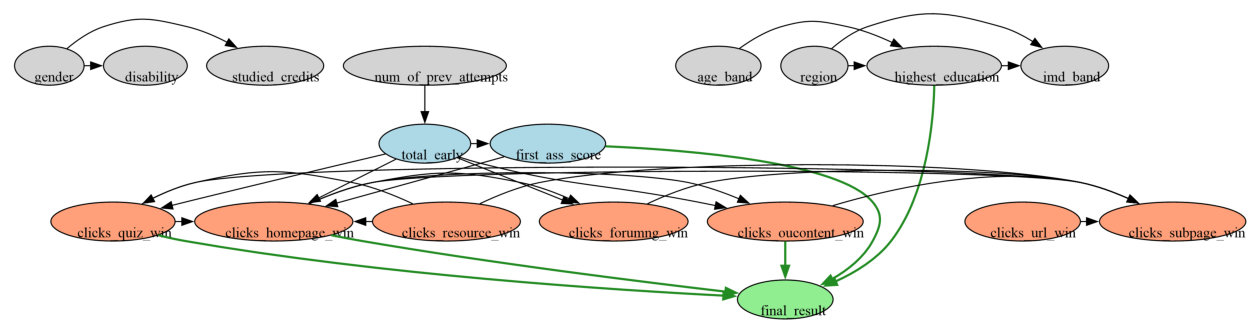

In [48]:
import io, pydot
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from causallearn.utils.GraphUtils import GraphUtils

dot_path = r"C:\Users\Disha Sharma\.conda\envs\analytics\Library\bin\dot.exe"   # full path: plain 'dot' fails here
pyd = GraphUtils.to_pydot(cg.G, labels=node_names)

def to_idx(x):
    # pydot may give a node reference as an int or as quoted text: turn both into a plain int
    return int(str(x).strip('"'))

tier_color = {0: 'lightgray', 1: 'lightblue', 2: 'lightsalmon', 3: 'lightgreen'}
for node in pyd.get_nodes():
    s = str(node.get_name()).strip('"')
    if not s.isdigit():
        continue                                     # skip pydot's default entries
    label = node_names[int(s)]
    node.set_style('filled'); node.set_fillcolor(tier_color[tier_of[label]])
    node.set_fontsize('10'); node.set_fixedsize('false'); node.set_margin('0.15,0.08')

for edge in pyd.get_edges():                         # edges touching the outcome in green
    src = node_names[to_idx(edge.get_source())]
    dst = node_names[to_idx(edge.get_destination())]
    if 'final_result' in (src, dst):
        edge.set_color('forestgreen'); edge.set_penwidth('2')

for t, names in tiers.items():                       # every variable of one tier on the same row
    sg = pydot.Subgraph(rank='same')
    for n in names:
        sg.add_node(pydot.Node(str(node_names.index(n))))
    pyd.add_subgraph(sg)

png_data = pyd.create_png(prog=dot_path)             # not pyd.write_png(): it calls plain 'dot'
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_PC_graph.png"), "wb") as f:
    f.write(png_data)
plt.figure(figsize=(16, 12))
plt.imshow(mpimg.imread(io.BytesIO(png_data)))
plt.axis('off')
plt.show()

### Stage 3.4 - Freeze the DAG: PC edges + early-context edges (+ outcome edges after Stage 4.5); roles and adjustment sets

In [75]:
import networkx as nx

# Decisions from Stage 4.5 (empty on the first run, filled in later, then rerun this cell)
outcome_edge_acts = globals().get('outcome_edge_acts', [])
recourse_levers = globals().get('recourse_levers', [])

dag = nx.DiGraph()
dag.add_nodes_from(node_names)
dag.add_edges_from(directed)                     # edges found by PC (no undirected pairs came out for CCC)

# Addition 1: what a student did before the window can influence what they do in it
ctx_edges = [(src, c) for c in win_acts for src in ['total_early', 'first_ass_score'] if not dag.has_edge(src, c)]
dag.add_edges_from(ctx_edges)
# Addition 2: activities with a clear effect on the outcome when all others are held fixed (Stage 4.5)
outcome_edges = [(c, 'final_result') for c in outcome_edge_acts if not dag.has_edge(c, 'final_result')]
dag.add_edges_from(outcome_edges)
assert nx.is_directed_acyclic_graph(dag), "graph has a cycle"
print("edges from PC:", len(directed), "| context edges added:", len(ctx_edges), "| outcome edges added:", len(outcome_edges))

edges_out = pd.DataFrame([(a, b, 'PC') for a, b in directed] +
                         [(a, b, 'added: early context') for a, b in ctx_edges] +
                         [(a, b, 'added: direct effect (Stage 4.5)') for a, b in outcome_edges],
                         columns=['from', 'to', 'source'])
edges_out.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_dag_edges.csv"), index=False)

# Role of every variable, whether it reaches the outcome, and its adjustment set (= its direct parents)
role = {0: 'immutable context', 1: 'fixed context (known at checkpoint)', 2: 'action-window activity', 3: 'outcome'}
rows = []                                        # reset so reruns do not duplicate rows
for n in node_names:
    if n == 'final_result':
        continue
    rows.append({'variable': n, 'role': role[tier_of[n]],
                 'path_to_outcome': nx.has_path(dag, n, 'final_result'),
                 'direct_to_outcome': dag.has_edge(n, 'final_result'),
                 'adjustment_set': sorted(dag.predecessors(n))})
roles = pd.DataFrame(rows)
roles.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_roles_adjustment_sets.csv"), index=False)
levers = roles[(roles.role == 'action-window activity') & roles.path_to_outcome].variable.tolist()
print("treatments for effect estimation:", levers)
print("recourse levers:", recourse_levers)
print(roles[['variable', 'path_to_outcome', 'direct_to_outcome']].to_string(index=False))

edges from PC: 29 | context edges added: 9 | outcome edges added: 1
treatments for effect estimation: ['clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win', 'clicks_resource_win']
recourse levers: ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_homepage_win']
            variable  path_to_outcome  direct_to_outcome
              gender            False              False
              region             True              False
   highest_education             True               True
            imd_band            False              False
            age_band             True              False
num_of_prev_attempts             True              False
     studied_credits            False              False
          disability            False              False
         total_early             True              False
     first_ass_score             True               True
  clicks_forumng_win             True               True
 clicks_homepage_win

### Stage 3.5 - Sensitivity: the same PC run with alpha 0.10 (sparse variables may gain edges)

In [54]:
cg10 = pc(data, alpha=0.10, indep_test=gsq, background_knowledge=bk, node_names=node_names, show_progress=False)

def edge_sets(cg_):
    # Split PC edges into directed pairs and undirected pairs
    d, u = set(), set()
    for e in cg_.G.get_graph_edges():
        a, b = e.get_node1().get_name(), e.get_node2().get_name()
        ea, eb = e.get_endpoint1().name, e.get_endpoint2().name
        if ea == 'TAIL' and eb == 'ARROW':
            d.add((a, b))
        elif ea == 'ARROW' and eb == 'TAIL':
            d.add((b, a))
        else:
            u.add(tuple(sorted((a, b))))
    return d, u

d05, u05 = set(directed), {tuple(sorted((a, b))) for a, b, _, _ in undirected}
d10, u10 = edge_sets(cg10)
print("edges at 0.05:", len(d05) + len(u05), "| at 0.10:", len(d10) + len(u10))
print("directed edges gained at 0.10:", sorted(d10 - d05))
print("directed edges lost at 0.10:", sorted(d05 - d10))
print("direct parents of final_result at 0.10:", sorted(a for a, b in d10 if b == 'final_result'))

edges at 0.05: 29 | at 0.10: 32
directed edges gained at 0.10: [('age_band', 'clicks_oucontent_win'), ('age_band', 'total_early'), ('clicks_oucontent_win', 'clicks_homepage_win'), ('clicks_subpage_win', 'clicks_forumng_win'), ('first_ass_score', 'clicks_forumng_win')]
directed edges lost at 0.10: [('age_band', 'highest_education'), ('clicks_forumng_win', 'clicks_subpage_win'), ('clicks_homepage_win', 'clicks_oucontent_win'), ('highest_education', 'imd_band'), ('region', 'highest_education'), ('region', 'imd_band')]
direct parents of final_result at 0.10: ['clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win', 'first_ass_score', 'highest_education']


### Stage 4.1 - Effect of each variable on final_result (DoWhy linear backdoor estimate, 95% interval, placebo and random-common-cause refutation)

In [77]:
import logging, warnings
from dowhy import CausalModel
warnings.filterwarnings('ignore')
logging.getLogger('dowhy').setLevel(logging.ERROR)

treatments = roles[roles.path_to_outcome].variable.tolist()      # every variable with a path to the outcome
print(len(treatments), "treatments:", treatments)

def estimate_one(t, adj):
    # One treatment at a time, adjusting only for its parents (the adjustment set)
    model = CausalModel(data=Gdf, treatment=t, outcome='final_result', common_causes=adj if adj else None)
    ident = model.identify_effect(proceed_when_unidentifiable=True)
    est = model.estimate_effect(ident, method_name="backdoor.linear_regression", confidence_intervals=True)
    ci = np.array(est.get_confidence_intervals(), dtype=float).flatten()
    out = {'ATE': float(est.value), 'CI_low': float(ci[0]), 'CI_high': float(ci[1])}
    try:   # refutation 1: a random fake treatment should have about zero effect
        r = model.refute_estimate(ident, est, method_name="placebo_treatment_refuter", placebo_type="permute", num_simulations=50)
        out['placebo_effect'] = float(r.new_effect)
        out['placebo_p'] = r.refutation_result.get('p_value') if isinstance(r.refutation_result, dict) else None
    except Exception as e:
        out['placebo_effect'], out['placebo_p'] = None, str(e)[:40]
    try:   # refutation 2: adding a random extra confounder should barely change the effect
        r = model.refute_estimate(ident, est, method_name="random_common_cause", num_simulations=50)
        out['random_cc_effect'] = float(r.new_effect)
    except Exception:
        out['random_cc_effect'] = None
    return out

results = []                         # reset before every rerun, otherwise reruns add duplicate rows
for t in treatments:
    adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]
    row = {'variable': t, 'role': roles.loc[roles.variable == t, 'role'].iloc[0],
           'adjustment_set': ', '.join(adj) if adj else '(none)'}
    row.update(estimate_one(t, adj))
    row['significant'] = (row['CI_low'] > 0) or (row['CI_high'] < 0)
    results.append(row)
    print("done:", t)
ate = pd.DataFrame(results)
cols = ['variable', 'role', 'ATE', 'CI_low', 'CI_high', 'significant', 'placebo_effect', 'placebo_p', 'random_cc_effect', 'adjustment_set']
print(ate[cols].round(3).to_string(index=False))
ate.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_ATE.csv"), index=False)

11 treatments: ['region', 'highest_education', 'age_band', 'num_of_prev_attempts', 'total_early', 'first_ass_score', 'clicks_forumng_win', 'clicks_homepage_win', 'clicks_oucontent_win', 'clicks_quiz_win', 'clicks_resource_win']
done: region
done: highest_education
done: age_band
done: num_of_prev_attempts
done: total_early
done: first_ass_score
done: clicks_forumng_win
done: clicks_homepage_win
done: clicks_oucontent_win
done: clicks_quiz_win
done: clicks_resource_win
            variable                                role    ATE  CI_low  CI_high  significant  placebo_effect  placebo_p  random_cc_effect                                                     adjustment_set
              region                   immutable context -0.006  -0.016    0.004        False           0.000      0.494            -0.006                                                             (none)
   highest_education                   immutable context  0.205   0.161    0.248         True          -0.004      

### Stage 4.2 - Robustness: effects under heavier adjustment, and why the focus activity effect shrinks step by step

In [61]:
import statsmodels.api as sm

context = ['total_early', 'first_ass_score']                 # known before the window: safe to adjust for
background = ['gender', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']
reg_dummies = pd.get_dummies(Gdf['region'], prefix='reg', drop_first=True).astype(float)   # region is nominal: dummies

def ols_effect(t, adj, with_region=False):
    # Same linear model DoWhy uses: outcome ~ treatment + adjustment variables
    parts = [Gdf[[t] + adj].astype(float)]
    if with_region:
        parts.append(reg_dummies)
    X_ = sm.add_constant(pd.concat(parts, axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    lo, hi = m.conf_int().loc[t]
    return round(m.params[t], 3), round(lo, 3), round(hi, 3)

rows = []                                                    # reset before every rerun
for t in levers:
    graph_adj = roles.loc[roles.variable == t, 'adjustment_set'].iloc[0]
    plus_ctx = sorted(set(graph_adj) | set(context))
    plus_all = sorted(set(plus_ctx) | set(background))
    rows.append({'activity': t, 'graph_set': ols_effect(t, graph_adj),
                 '+context': ols_effect(t, plus_ctx), '+context+background': ols_effect(t, plus_all, with_region=True)})
print(pd.DataFrame(rows).to_string(index=False))

focus_win = f'clicks_{FOCUS_ACT}_win'
g_adj = roles.loc[roles.variable == focus_win, 'adjustment_set'].iloc[0]
steps = [('nothing', []), ('+ early clicks', ['total_early']), ('+ first assessment', context),
         ('+ graph set', sorted(set(g_adj) | set(context))), ('+ background', sorted(set(g_adj) | set(context) | set(background)))]
q = [{'adjusted for': l, 'effect (ATE, CI low, CI high)': ols_effect(focus_win, a, with_region=('background' in l))} for l, a in steps]
print("\nFocus activity effect, step by step:")
print(pd.DataFrame(q).to_string(index=False))

            activity              graph_set               +context   +context+background
 clicks_homepage_win  (0.115, 0.064, 0.166)  (0.115, 0.064, 0.166) (0.115, 0.064, 0.166)
clicks_oucontent_win (0.005, -0.028, 0.038) (0.005, -0.028, 0.038) (0.014, -0.02, 0.047)
     clicks_quiz_win  (0.163, 0.132, 0.194)  (0.163, 0.132, 0.194)  (0.161, 0.13, 0.192)
 clicks_resource_win   (0.071, 0.04, 0.102)   (0.071, 0.04, 0.102) (0.068, 0.037, 0.099)

Focus activity effect, step by step:
      adjusted for effect (ATE, CI low, CI high)
           nothing         (0.297, 0.269, 0.326)
    + early clicks          (0.21, 0.177, 0.243)
+ first assessment             (0.17, 0.14, 0.2)
       + graph set         (0.163, 0.132, 0.194)
      + background          (0.161, 0.13, 0.192)


### Stage 4.3 - Where did the whole-course quiz effect go? Same simple model on three samples, then "any activity vs none"

In [70]:
base = feat.copy()                                           # all students, quiz clicks up to day 56
base['y'] = base.final_result.map({'Withdrawn': 0, 'Fail': 1, 'Pass': 2, 'Distinction': 3})

def simple_effect(d, qcol, label):
    # Quartile-bin the quiz clicks inside this sample, then regress the outcome on the bin number
    b = pd.qcut(d[qcol], q=4, labels=False, duplicates='drop').astype(float).rename('bin')
    m = sm.OLS(d['y'].astype(float), sm.add_constant(b)).fit()
    lo, hi = m.conf_int().loc['bin']
    return {'sample': label, 'n': len(d), 'effect_per_bin': round(m.params['bin'], 3), 'CI': (round(lo, 3), round(hi, 3))}

rows = [simple_effect(base, 'focus_clicks_d56', 'all students, clicks up to day 56'),
        simple_effect(base[base.enrolled_d56], 'focus_clicks_d56', 'enrolled at day 56, clicks up to day 56')]
win_df = pd.DataFrame({'y': G.final_result, 'q': X.loc[G.index, focus_win]})
rows.append(simple_effect(win_df, 'q', 'enrolled at day 56, window clicks only'))
print(pd.DataFrame(rows).to_string(index=False))

any_focus = (X.loc[G.index, focus_win] > 0).astype(float).rename('any_focus')
adj_focus = sorted(set(g_adj) | set(context))
Xd = sm.add_constant(pd.concat([any_focus, Gdf[adj_focus].astype(float)], axis=1))
mm = sm.OLS(Gdf['final_result'].astype(float), Xd).fit()
lo, hi = mm.conf_int().loc['any_focus']
print("share with any quiz clicks in the window:", round(any_focus.mean() * 100, 1), "%")
print("effect of any vs none:", round(mm.params['any_focus'], 3), (round(lo, 3), round(hi, 3)))

                                 sample    n  effect_per_bin             CI
      all students, clicks up to day 56 4434           0.484 (0.459, 0.508)
enrolled at day 56, clicks up to day 56 3239           0.311 (0.282, 0.341)
 enrolled at day 56, window clicks only 3239           0.406 (0.366, 0.445)
share with any quiz clicks in the window: 60.3 %
effect of any vs none: 0.238 (0.167, 0.309)


### Stage 4.4 - Each activity level versus no activity (adjusted for early clicks and first assessment only)

In [64]:
context_vars = ['total_early', 'first_ass_score']

def level_effects(t):
    # Effect of level 1, 2, 3 versus level 0 (no activity)
    d = pd.get_dummies(Gdf[t].astype(int), prefix='lvl').astype(float).drop(columns='lvl_0')
    X_ = sm.add_constant(pd.concat([d, Gdf[context_vars].astype(float)], axis=1))
    m = sm.OLS(Gdf['final_result'].astype(float), X_).fit()
    out = {'activity': short(t), '% with none': round((Gdf[t] == 0).mean() * 100, 1)}
    for lv in ['lvl_1', 'lvl_2', 'lvl_3']:
        if lv in m.params.index:
            lo, hi = m.conf_int().loc[lv]
            out[lv.replace('lvl_', 'level ') + ' vs none'] = f"{m.params[lv]:.3f} ({lo:.3f}, {hi:.3f})"
        else:
            out[lv.replace('lvl_', 'level ') + ' vs none'] = 'n/a'     # url has only 3 levels in CCC
    return out

print("Effect on final_result (0-3) versus no activity; level 1 = lowest third of active students")
print(pd.DataFrame([level_effects(t) for t in win_acts]).to_string(index=False))

Effect on final_result (0-3) versus no activity; level 1 = lowest third of active students
 activity  % with none       level 1 vs none       level 2 vs none      level 3 vs none
  forumng         43.3 0.049 (-0.035, 0.132)  0.147 (0.061, 0.234) 0.281 (0.186, 0.376)
 homepage          6.9 0.044 (-0.085, 0.173)  0.188 (0.053, 0.324) 0.473 (0.326, 0.620)
oucontent         44.1  0.218 (0.133, 0.304)  0.238 (0.148, 0.328) 0.157 (0.063, 0.251)
     quiz         39.7  0.133 (0.050, 0.216)  0.243 (0.156, 0.331) 0.551 (0.456, 0.646)
 resource         16.8 0.038 (-0.057, 0.132)  0.155 (0.059, 0.250) 0.190 (0.088, 0.291)
  subpage         11.5 0.089 (-0.017, 0.196)  0.208 (0.095, 0.321) 0.407 (0.287, 0.527)
      url         49.1 0.046 (-0.022, 0.113) 0.053 (-0.035, 0.141)                  n/a


### Stage 4.5 - All activities together, split into participation (any vs none) and volume (each extra level)

In [67]:
parts = {}
for t in win_acts:
    lvl = Gdf[t].astype(int)
    parts[short(t) + '_any'] = (lvl > 0).astype(float)               # participation: any activity vs none
    parts[short(t) + '_more'] = (lvl - 1).clip(lower=0).astype(float)  # volume: levels above the first

Xj2 = sm.add_constant(pd.concat([pd.DataFrame(parts), Gdf[context_vars].astype(float)], axis=1))
mj2 = sm.OLS(Gdf['final_result'].astype(float), Xj2).fit()            # one regression, all activities together
ci = mj2.conf_int()
res = pd.DataFrame({'effect': mj2.params, 'lo': ci[0], 'hi': ci[1]})
rows = []                                                             # reset before every rerun
for t in win_acts:
    r = {'activity': short(t)}
    for kind, label in [('_any', 'participation (any vs none)'), ('_more', 'volume (per extra level)')]:
        e = res.loc[short(t) + kind]
        r[label] = f"{e.effect:.3f} ({e.lo:.3f}, {e.hi:.3f})"
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("R-squared:", round(mj2.rsquared, 3))
res.round(3).to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_participation_volume_effects.csv"))

 activity participation (any vs none) volume (per extra level)
  forumng      -0.007 (-0.088, 0.073)     0.067 (0.014, 0.120)
 homepage      -0.044 (-0.224, 0.136)     0.101 (0.039, 0.164)
oucontent        0.128 (0.043, 0.212)  -0.079 (-0.130, -0.027)
     quiz       0.037 (-0.047, 0.120)     0.173 (0.120, 0.226)
 resource      -0.038 (-0.156, 0.081)   -0.003 (-0.050, 0.045)
  subpage       0.075 (-0.090, 0.240)    0.033 (-0.025, 0.091)
      url      -0.017 (-0.087, 0.053)   -0.054 (-0.145, 0.037)
R-squared: 0.292


### Stage 5.0 - Record the decisions, then rerun Stage 3.4 and Stage 4.1

In [73]:
# Decisions for CCC (content pages left out of the levers, strict rule)
part_nodes = []                                                     # no start-type lever in CCC
vol_nodes = ['clicks_quiz_win', 'clicks_forumng_win', 'clicks_homepage_win']   # raise by one level
outcome_edge_acts = ['clicks_forumng_win']                          # direct edge to add (PC did not link forum to the outcome)
recourse_levers = part_nodes + vol_nodes
# Now rerun Stage 3.4 (it reads outcome_edge_acts and recourse_levers), then Stage 4.1.

### Stage 5.1 - Fit the invertible causal model on the frozen DAG and check it (fit, invertibility, graph structure)

nodes: 12 | edges: 25
region | EmpiricalDistribution | NoneType
highest_education | DiscreteAdditiveNoiseModel | SklearnRegressionModel
age_band | EmpiricalDistribution | NoneType
num_of_prev_attempts | EmpiricalDistribution | NoneType
total_early | DiscreteAdditiveNoiseModel | SklearnRegressionModel
first_ass_score | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_forumng_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_homepage_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_oucontent_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_quiz_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
clicks_resource_win | DiscreteAdditiveNoiseModel | SklearnRegressionModel
final_result | DiscreteAdditiveNoiseModel | SklearnRegressionModel


Test permutations of given graph: 100%|██████████| 50/50 [05:27<00:00,  6.55s/it]


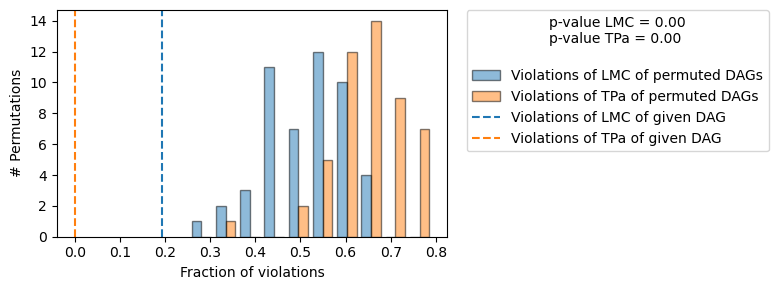

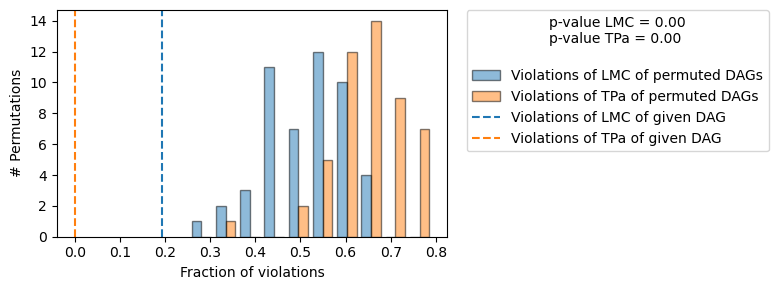

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
--- Node region
--- Node age_band
--- Node num_of_prev_attempts
--- Node highest_education
- The R2 coefficient is -0.005873849539485954.
--- Node total_early
- The R2 coefficient is -0.15783108595227388.
--- Node first_ass_score
- The R2 coefficient is 0.16860278524331.
--- Node clicks_resource_win
- The R2 coefficient is 0.0186687628189957.
--- Node clicks_quiz_win
- The R2 coefficient is 0.26254336272851575.
--- Node clicks_homepage_win
- The R2 coefficient is 0.5362479406571473.
--- Node clicks_forumng_win
- The R2 coefficient is 0.2883110173728046.
--- Node click

In [80]:
import dowhy.gcm as gcm
import pickle
try:
    from dowhy.graph import get_ordered_predecessors          # path in this DoWhy version
except ImportError:
    get_ordered_predecessors = lambda g, n: sorted(g.predecessors(n))

# Model variables = variables with a path to the outcome, plus the outcome
scm_cols = roles[roles.path_to_outcome].variable.tolist() + ['final_result']
dag_scm = dag.subgraph(scm_cols).copy()
df_scm = Gdf[scm_cols].astype(float)                           # gcm wants numeric data
print("nodes:", dag_scm.number_of_nodes(), "| edges:", dag_scm.number_of_edges())

scm = gcm.InvertibleStructuralCausalModel(dag_scm.copy())      # invertible: each student keeps their own noise
gcm.auto.assign_causal_mechanisms(scm, df_scm)
for n in dag_scm.nodes:
    mech = scm.causal_mechanism(n)
    print(n, "|", type(mech).__name__, "|", type(getattr(mech, "prediction_model", None)).__name__)

gcm.fit(scm, df_scm)
ev = gcm.evaluate_causal_model(scm, df_scm, compare_mechanism_baselines=True)   # slow: keep the laptop awake
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm.pkl"), "wb") as f:
    pickle.dump(scm, f)
with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_evaluation.txt"), "w") as f:
    f.write(str(ev))
for line in str(ev).splitlines():
    if any(k in line for k in ["--- Node", "R2 coefficient", "model assumption", "violates", "overall average KL"]):
        print(line)

### Stage 5.2a - Helpers: read the evaluation report, and build a model on its OWN copy of the graph

In [85]:
import re

def to_num(s):
    # Report sentences end with a full stop right after the number
    return float(s.rstrip('.'))

def parse_eval(text):
    # Pull R-squared and the invertibility result per node out of the report text
    r2, inv, cur = {}, {}, None
    for line in text.splitlines():
        m = re.match(r'--- Node (\S+)', line)
        if m:
            cur = m.group(1)
            continue
        m = re.search(r'The R2 coefficient is ([\-0-9.eE+]+)', line)
        if m and cur:
            r2[cur] = to_num(m.group(1))
        m = re.search(r'assumption for node (\S+) is (not rejected|rejected) with a p-value of ([0-9.eE+\-]+)', line)
        if m:
            inv[m.group(1)] = (m.group(2), to_num(m.group(3)))
    return r2, inv

def build_scm(variant, data, graph):
    # IMPORTANT: every model gets its OWN copy of the graph. Models built on one shared graph overwrite each other.
    s = gcm.InvertibleStructuralCausalModel(graph.copy())
    gcm.auto.assign_causal_mechanisms(s, data)                # roots keep their empirical distributions
    if variant == 'auto':
        return s
    for n in graph.nodes:
        if graph.in_degree(n) == 0:
            continue
        reg = gcm.ml.create_linear_regressor() if variant == 'linear' else gcm.ml.create_hist_gradient_boost_regressor()
        s.set_causal_mechanism(n, gcm.AdditiveNoiseModel(reg))
    return s

def comparison_table(reports, graph):
    # One row per non-root node, one R-squared and invertibility column pair per model
    rows = []
    for n in [x for x in graph.nodes if graph.in_degree(x) > 0]:
        row = {'node': n}
        for v, (r2, inv) in reports.items():
            row[v + ' R2'] = round(r2.get(n, np.nan), 3)
            row[v + ' invertible'] = f"{'no' if inv.get(n, ('', 0))[0] == 'rejected' else 'yes'} (p={inv.get(n, ('', np.nan))[1]:.3g})"
        rows.append(row)
    return pd.DataFrame(rows)

### Stage 5.2b - Compare mechanism types on the level-coded data: automatic, linear, boosted (fit and invertibility per node)

In [87]:
reports = {}                                       # reset so reruns do not mix old results
for v in ['auto', 'linear', 'boosted']:
    s = build_scm(v, df_scm, dag_scm)
    gcm.fit(s, df_scm)
    # skip the slow structure test and KL here: only per-node fit and invertibility are needed
    ev_v = gcm.evaluate_causal_model(s, df_scm, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    reports[v] = parse_eval(str(ev_v))
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_levels.pkl"), "wb") as f:
        pickle.dump(s, f)
comp = comparison_table(reports, dag_scm)
print(comp.to_string(index=False))
comp.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_mechanism_comparison.csv"), index=False)

Evaluating causal mechanisms...: 100%|██████████| 12/12 [00:00<00:00, 2403.61it/s]


                node  auto R2 auto invertible  linear R2 linear invertible  boosted R2 boosted invertible
   highest_education    0.005    no (p=5e-14)      0.035    no (p=7.6e-06)       0.075    no (p=2.53e-07)
         total_early   -0.156  no (p=0.00986)      0.012         yes (p=1)       0.010          yes (p=1)
     first_ass_score    0.167        no (p=0)      0.197   no (p=0.000859)       0.215    no (p=0.000606)
  clicks_forumng_win    0.295        no (p=0)      0.355          no (p=0)       0.358           no (p=0)
 clicks_homepage_win    0.538 no (p=0.000127)      0.617          no (p=0)       0.621           no (p=0)
clicks_oucontent_win    0.316        no (p=0)      0.380          no (p=0)       0.380           no (p=0)
     clicks_quiz_win    0.258        no (p=0)      0.326          no (p=0)       0.322           no (p=0)
 clicks_resource_win    0.013  no (p=0.00226)      0.111    no (p=3.8e-05)       0.111    no (p=1.22e-05)
        final_result    0.207 no (p=0.000365) 

### Stage 5.2c - Rebuild the models for the later stages (CCC has no start-type activity, so no 0/1 recoding) and check the lever coefficients

In [90]:
# CCC has no start-type activity (part_nodes is empty), so the data stays level-coded
df_scm2 = df_scm.copy()
for c in part_nodes:                               # does nothing for CCC
    df_scm2[c] = (df_scm2[c] > 0).astype(float)

scms2, reports2 = {}, {}                           # reset so reruns do not mix old results
for v in ['linear', 'boosted']:
    s = build_scm(v, df_scm2, dag_scm)             # each model on its own copy of the graph
    gcm.fit(s, df_scm2)
    ev_v = gcm.evaluate_causal_model(s, df_scm2, compare_mechanism_baselines=False,
                                     evaluate_causal_structure=False, evaluate_overall_kl_divergence=False)
    scms2[v] = s
    reports2[v] = parse_eval(str(ev_v))
    with open(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_scm_{v}_participation.pkl"), "wb") as f:
        pickle.dump(s, f)                          # name kept for the later stages; same as the level-coded model here

# The outcome mechanism of the linear model: effect per parent (one level step)
lin2 = scms2['linear'].causal_mechanism('final_result').prediction_model.sklearn_model
par2 = get_ordered_predecessors(scms2['linear'].graph, 'final_result')
coefs = pd.Series(lin2.coef_.ravel(), index=par2)
print("linear outcome mechanism (effect per level):")
print(coefs.round(3).to_string())

# Compare the three levers with their per-level effects from Stage 4.5 (res comes from that cell)
cmp = pd.DataFrame({'linear model coefficient': [coefs[n] for n in vol_nodes],
                    'Stage 4.5 per-level effect': [res.loc[short(n) + '_more', 'effect'] for n in vol_nodes]},
                   index=[short(n) for n in vol_nodes]).round(3)
print("\nLever coefficients versus Stage 4.5:")
print(cmp.to_string())
print("\noutcome R-squared:", {v: round(reports2[v][0]['final_result'], 3) for v in reports2})

Evaluating causal mechanisms...: 100%|██████████| 12/12 [00:00<00:00, 2356.57it/s]


linear outcome mechanism (effect per level):
clicks_forumng_win      0.043
clicks_homepage_win     0.077
clicks_oucontent_win   -0.002
clicks_quiz_win         0.130
first_ass_score         0.430
highest_education       0.126

Lever coefficients versus Stage 4.5:
          linear model coefficient  Stage 4.5 per-level effect
quiz                         0.130                       0.173
forumng                      0.043                       0.067
homepage                     0.077                       0.101

outcome R-squared: {'linear': 0.292, 'boosted': 0.247}


### Stage 5.3 - What-if shifts: raise each lever one level, and all three together (Fail and late leavers)

In [93]:
cohort_lab = G.loc[df_scm2.index, 'cohort']              # 'fail', 'late_leaver' or 'success' per row

def raise_to(nodes, level=1):
    # Raise-only: students already at or above the level are left unchanged (not used in CCC: no start-type lever)
    return {n: (lambda x, l=level: np.maximum(x, l)) for n in nodes}

def step_up(nodes):
    # One level more, capped at level 3
    return {n: (lambda x: np.minimum(x + 1, 3)) for n in nodes}

# The actions we may recommend (from Stage 5.0): all three are 'raise one level'
actions = {short(n): raise_to([n]) for n in part_nodes}        # empty in CCC
actions.update({short(n) + '_up': step_up([n]) for n in vol_nodes})

def merge_actions(names):
    # Combine several actions into one set of interventions
    iv = {}
    for a in names:
        iv.update(actions[a])
    return iv

scenarios = {a: actions[a] for a in actions}                   # each action alone
scenarios['all actions'] = merge_actions(list(actions))        # all three together (no 'all starts' in CCC)

rows = []                                                      # reset before every rerun
for model_name, model in scms2.items():
    for cname in ['fail', 'late_leaver']:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)      # student-level what-if (approximate)
            shift = cf['final_result'].values - d['final_result'].values
            elig = np.zeros(len(d), dtype=bool)                              # students the action actually changes
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, 'n': len(d),
                         '% affected': round(elig.mean() * 100, 1),
                         'mean shift (all)': round(shift.mean(), 3),
                         'mean shift (affected)': round(shift[elig].mean(), 3) if elig.any() else np.nan})
res2 = pd.DataFrame(rows)
res2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_whatif_shifts_participation.csv"), index=False)
print(res2[res2.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nMean shift among affected students, linear vs boosted:")
print(res2.pivot_table(index=['cohort', 'scenario'], columns='model', values='mean shift (affected)').round(3).to_string())

     cohort    scenario   n  % affected  mean shift (all)  mean shift (affected)
       fail     quiz_up 781        89.6             0.138                  0.154
       fail  forumng_up 781        90.5             0.039                  0.043
       fail homepage_up 781        86.0             0.086                  0.100
       fail all actions 781        97.6             0.251                  0.257
late_leaver     quiz_up 780        92.3             0.142                  0.154
late_leaver  forumng_up 780        88.2             0.038                  0.043
late_leaver homepage_up 780        81.5             0.082                  0.100
late_leaver all actions 780        97.6             0.248                  0.254

Mean shift among affected students, linear vs boosted:
model                    boosted  linear
cohort      scenario                    
fail        all actions    0.270   0.257
            forumng_up     0.062   0.043
            homepage_up    0.142   0.100
          

### Stage 5.4 - Chance of reaching the target before and after each action (noise from the whole sample, no student-level noise recovery)

In [96]:
def outcome_mean(model, data):
    # Predicted outcome without noise. .ravel() because the linear model returns a column, the boosted one a flat list
    mech = model.causal_mechanism('final_result')
    par = get_ordered_predecessors(model.graph, 'final_result')
    return np.asarray(mech.prediction_model.predict(data[par].to_numpy())).ravel()

def prob_reach(f_vals, resid, T):
    # For each student: share of noise draws for which predicted outcome + noise reaches the target T
    assert f_vals.ndim == 1 and resid.ndim == 1, "predictions and residuals must both be flat"
    return (f_vals[:, None] + resid[None, :] >= T).mean(axis=1)

targets = {'fail': 1.5, 'late_leaver': 0.5}      # Fail: reach Pass (>= 1.5); late leaver: stay, not withdraw (>= 0.5)
rows, calib = [], []                             # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = df_scm2['final_result'].values - f_all                  # pool of unexplained variation, all enrolled students
    for T, real in [(1.5, (df_scm2.final_result >= 2).mean()), (0.5, (df_scm2.final_result >= 1).mean())]:
        calib.append({'model': model_name, 'target': T,
                      'model average': round(prob_reach(f_all, resid, T).mean(), 3), 'real share': round(real, 3)})
    for cname, T in targets.items():
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T)                               # chance now
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)
            delta = cf['final_result'].values - d['final_result'].values
            p1 = prob_reach(f0 + delta, resid, T)                   # chance after the action
            elig = np.zeros(len(d), dtype=bool)
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, '% affected': round(elig.mean() * 100, 1),
                         'chance before (%)': round(p0.mean() * 100, 1), 'chance after (%)': round(p1.mean() * 100, 1),
                         'gain, all (pts)': round((p1 - p0).mean() * 100, 1),
                         'gain, affected (pts)': round((p1 - p0)[elig].mean() * 100, 1) if elig.any() else np.nan})
print("Sanity check (model average vs real share; should be within about 3 points):")
print(pd.DataFrame(calib).to_string(index=False))
res_p = pd.DataFrame(rows)
res_p.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_probability_gains.csv"), index=False)
print("\nMAIN MODEL (linear):")
print(res_p[res_p.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nGain among affected students (points), linear vs boosted:")
print(res_p.pivot_table(index=['cohort', 'scenario'], columns='model', values='gain, affected (pts)').round(1).to_string())

Sanity check (model average vs real share; should be within about 3 points):
  model  target  model average  real share
 linear     1.5          0.502       0.518
 linear     0.5          0.813       0.759
boosted     1.5          0.482       0.518
boosted     0.5          0.821       0.759

MAIN MODEL (linear):
     cohort    scenario  % affected  chance before (%)  chance after (%)  gain, all (pts)  gain, affected (pts)
       fail     quiz_up        89.6               36.7              42.6              5.9                   6.5
       fail  forumng_up        90.5               36.7              38.4              1.7                   1.8
       fail homepage_up        86.0               36.7              40.4              3.6                   4.2
       fail all actions        97.6               36.7              47.3             10.5                  10.8
late_leaver     quiz_up        92.3               75.0              78.7              3.7                   4.0
late_leaver  f

### Stage 5.4 (rerun) - Chance of reaching the target, with noise drawn from students with a similar predicted outcome

In [99]:
def outcome_mean(model, data):
    # Predicted outcome without noise. .ravel() because the linear model returns a column, the boosted one a flat list
    mech = model.causal_mechanism('final_result')
    par = get_ordered_predecessors(model.graph, 'final_result')
    return np.asarray(mech.prediction_model.predict(data[par].to_numpy())).ravel()

def make_pools(f_all, resid, n_bins=20):
    # Group enrolled students by predicted outcome; each group keeps its own pool of leftover errors
    inner = np.unique(np.quantile(f_all, np.linspace(0, 1, n_bins + 1))[1:-1])   # bin edges (inner ones)
    grp = np.digitize(f_all, inner)
    pools = {b: resid[grp == b] for b in np.unique(grp)}
    return inner, pools

def prob_reach_local(f_vals, bins, pools, T):
    # For each student: share of noise draws, taken from the student's own bin, that reach the target T
    out = np.zeros(len(f_vals))
    for b in np.unique(bins):
        idx = np.where(bins == b)[0]
        out[idx] = (f_vals[idx][:, None] + pools[b][None, :] >= T).mean(axis=1)
    return out

targets = {'fail': 1.5, 'late_leaver': 0.5}      # Fail: reach Pass (>= 1.5); late leaver: stay, not withdraw (>= 0.5)
rows, calib = [], []                             # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = df_scm2['final_result'].values - f_all                  # leftover error of every enrolled student
    inner, pools = make_pools(f_all, resid)
    bins_all = np.digitize(f_all, inner)
    for T, real in [(1.5, (df_scm2.final_result >= 2).mean()), (0.5, (df_scm2.final_result >= 1).mean())]:
        calib.append({'model': model_name, 'target': T,
                      'model average': round(prob_reach_local(f_all, bins_all, pools, T).mean(), 3),
                      'real share': round(real, 3)})
    for cname, T in targets.items():
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        b0 = np.digitize(f0, inner)                                 # the student keeps this pool before and after
        p0 = prob_reach_local(f0, b0, pools, T)                     # chance now
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)
            delta = cf['final_result'].values - d['final_result'].values
            p1 = prob_reach_local(f0 + delta, b0, pools, T)         # chance after the action
            elig = np.zeros(len(d), dtype=bool)
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, '% affected': round(elig.mean() * 100, 1),
                         'chance before (%)': round(p0.mean() * 100, 1), 'chance after (%)': round(p1.mean() * 100, 1),
                         'gain, all (pts)': round((p1 - p0).mean() * 100, 1),
                         'gain, affected (pts)': round((p1 - p0)[elig].mean() * 100, 1) if elig.any() else np.nan})
print("Sanity check (model average vs real share; should be within about 3 points):")
print(pd.DataFrame(calib).to_string(index=False))
res_p = pd.DataFrame(rows)
res_p.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_probability_gains.csv"), index=False)
print("\nMAIN MODEL (linear):")
print(res_p[res_p.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nGain among affected students (points), linear vs boosted:")
print(res_p.pivot_table(index=['cohort', 'scenario'], columns='model', values='gain, affected (pts)').round(1).to_string())

Sanity check (model average vs real share; should be within about 3 points):
  model  target  model average  real share
 linear     1.5          0.518       0.518
 linear     0.5          0.759       0.759
boosted     1.5          0.518       0.518
boosted     0.5          0.759       0.759

MAIN MODEL (linear):
     cohort    scenario  % affected  chance before (%)  chance after (%)  gain, all (pts)  gain, affected (pts)
       fail     quiz_up        89.6               35.0              35.0              0.0                   0.0
       fail  forumng_up        90.5               35.0              35.0              0.0                   0.0
       fail homepage_up        86.0               35.0              35.0              0.0                   0.0
       fail all actions        97.6               35.0              35.2              0.2                   0.2
late_leaver     quiz_up        92.3               69.2              69.2              0.0                   0.0
late_leaver  f

### Stage 5.4 (rerun 2) - Chance of reaching the target: one noise pool, with the cut-off calibrated to the real share

In [102]:
def outcome_mean(model, data):
    # Predicted outcome without noise. .ravel() because the linear model returns a column, the boosted one a flat list
    mech = model.causal_mechanism('final_result')
    par = get_ordered_predecessors(model.graph, 'final_result')
    return np.asarray(mech.prediction_model.predict(data[par].to_numpy())).ravel()

def prob_reach(f_vals, resid, T):
    # For each student: share of leftover errors (whole enrolled sample) for which prediction + error reaches T
    # Same answer as the earlier version, but sorted so it needs no big table
    assert f_vals.ndim == 1 and resid.ndim == 1, "predictions and residuals must both be flat"
    rs = np.sort(resid)
    return (len(rs) - np.searchsorted(rs, T - f_vals, side='left')) / len(rs)

def calibrated_T(f_all, resid, real_share):
    # Find the cut-off at which the average chance over all enrolled students equals the real share
    lo, hi = -2.0, 5.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if prob_reach(f_all, resid, mid).mean() > real_share:
            lo = mid                                  # chance too high: raise the bar
        else:
            hi = mid
    return (lo + hi) / 2

y_all = df_scm2['final_result'].values
nominal_T = {'fail': 1.5, 'late_leaver': 0.5}                         # Pass; not withdrawn
real_share = {'fail': (y_all >= 2).mean(), 'late_leaver': (y_all >= 1).mean()}

rows, calib = [], []                                                  # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = y_all - f_all                                             # one pool: all enrolled students
    T_cal = {c: calibrated_T(f_all, resid, real_share[c]) for c in nominal_T}
    for c in nominal_T:
        calib.append({'model': model_name, 'target': c, 'nominal T': nominal_T[c],
                      'average at nominal T': round(prob_reach(f_all, resid, nominal_T[c]).mean(), 3),
                      'real share': round(real_share[c], 3), 'calibrated T': round(T_cal[c], 3)})
    for cname in nominal_T:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T_cal[cname])                      # chance now
        for sname, iv in scenarios.items():
            cf = gcm.counterfactual_samples(model, iv, observed_data=d)
            delta = cf['final_result'].values - d['final_result'].values
            p1 = prob_reach(f0 + delta, resid, T_cal[cname])          # chance after the action
            elig = np.zeros(len(d), dtype=bool)
            for n, fn in iv.items():
                elig |= (np.asarray(fn(d[n].values)) != d[n].values)
            rows.append({'model': model_name, 'cohort': cname, 'scenario': sname, '% affected': round(elig.mean() * 100, 1),
                         'chance before (%)': round(p0.mean() * 100, 1), 'chance after (%)': round(p1.mean() * 100, 1),
                         'gain, all (pts)': round((p1 - p0).mean() * 100, 1),
                         'gain, affected (pts)': round((p1 - p0)[elig].mean() * 100, 1) if elig.any() else np.nan})
print("Calibration (average at the nominal cut-off versus the real share, and the calibrated cut-off):")
print(pd.DataFrame(calib).to_string(index=False))
res_p = pd.DataFrame(rows)
res_p.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_probability_gains.csv"), index=False)
print("\nMAIN MODEL (linear):")
print(res_p[res_p.model == 'linear'].drop(columns='model').to_string(index=False))
print("\nGain among affected students (points), linear vs boosted:")
print(res_p.pivot_table(index=['cohort', 'scenario'], columns='model', values='gain, affected (pts)').round(1).to_string())

Calibration (average at the nominal cut-off versus the real share, and the calibrated cut-off):
  model      target  nominal T  average at nominal T  real share  calibrated T
 linear        fail        1.5                 0.502       0.518         1.458
 linear late_leaver        0.5                 0.813       0.759         0.717
boosted        fail        1.5                 0.482       0.518         1.409
boosted late_leaver        0.5                 0.821       0.759         0.737

MAIN MODEL (linear):
     cohort    scenario  % affected  chance before (%)  chance after (%)  gain, all (pts)  gain, affected (pts)
       fail     quiz_up        89.6               38.5              44.3              5.8                   6.4
       fail  forumng_up        90.5               38.5              40.1              1.6                   1.8
       fail homepage_up        86.0               38.5              42.2              3.6                   4.2
       fail all actions        97.6    

### Stage 5.5 - Recourse plans: for each student, the smallest set of actions that raises the chance by at least g points

In [105]:
from itertools import combinations
from collections import Counter

def effective(d, iv):
    # Which students does this action actually change?
    e = np.zeros(len(d), dtype=bool)
    for n, fn in iv.items():
        e |= (np.asarray(fn(d[n].values)) != d[n].values)
    return e

gains_grid = [3, 5, 10, 15, 20]                    # minimum improvement in the chance, in points (3 added for CCC)
plan_levels = [5, 10]                              # thresholds for the 'most common plan' printout
cover_rows, plan_counts = [], {}                   # reset before every rerun
for model_name, model in scms2.items():
    f_all = outcome_mean(model, df_scm2)
    resid = y_all - f_all                          # one noise pool: all enrolled students
    T_cal = {c: calibrated_T(f_all, resid, real_share[c]) for c in nominal_T}    # this model's calibrated cut-offs
    for cname in nominal_T:
        d = df_scm2[cohort_lab == cname].reset_index(drop=True)
        f0 = outcome_mean(model, d)
        p0 = prob_reach(f0, resid, T_cal[cname])
        elig = {a: effective(d, iv) for a, iv in actions.items()}
        plan_gain, plan_valid = {}, {}
        for r in range(1, len(actions) + 1):
            for S in combinations(actions, r):         # every combination of actions
                iv = merge_actions(S)
                cf = gcm.counterfactual_samples(model, iv, observed_data=d)
                delta = cf['final_result'].values - d['final_result'].values
                plan_gain[S] = (prob_reach(f0 + delta, resid, T_cal[cname]) - p0) * 100
                plan_valid[S] = np.all([elig[a] for a in S], axis=0)    # every action in the plan applies to the student
        none_available = ~np.any(list(elig.values()), axis=0)
        for g in gains_grid:                            # share of students with a plan of at most k actions reaching g points
            row = {'model': model_name, 'cohort': cname, 'min gain (pts)': g}
            for k in range(1, len(actions) + 1):
                ok = np.zeros(len(d), dtype=bool)
                for S in plan_gain:
                    if len(S) <= k:
                        ok |= plan_valid[S] & (plan_gain[S] >= g)
                row[f'<= {k} actions (%)'] = round(ok.mean() * 100, 1)
            cover_rows.append(row)
        for g in plan_levels:                           # most common minimal plan: fewest actions, then larger gain
            plans = []
            for i in range(len(d)):
                best = None
                for S in plan_gain:
                    if plan_valid[S][i] and plan_gain[S][i] >= g:
                        key = (len(S), -plan_gain[S][i])
                        if best is None or key < best[0]:
                            best = (key, S)
                plans.append(' + '.join(best[1]) if best else ('no action applies' if none_available[i] else f'no plan reaches {g} pts'))
            plan_counts[(model_name, cname, g)] = Counter(plans)

cover = pd.DataFrame(cover_rows)
cover.to_csv(os.path.join(OUT_DIR, f"{MODULE}_checkpoint_recourse_coverage.csv"), index=False)
print(cover.to_string(index=False))
for (m, c, g), cnt in plan_counts.items():
    if m == 'linear':
        print(f"\nMost common minimal plans, {c}, gain >= {g} points ({m} model):")
        for plan, n in cnt.most_common(6):
            print(f"  {plan}: {n} students ({n / sum(cnt.values()) * 100:.1f}%)")

  model      cohort  min gain (pts)  <= 1 actions (%)  <= 2 actions (%)  <= 3 actions (%)
 linear        fail               3              91.0              92.8              92.8
 linear        fail               5              71.7              89.0              90.0
 linear        fail              10               0.0              48.1              62.1
 linear        fail              15               0.0               0.0               7.2
 linear        fail              20               0.0               0.0               0.0
 linear late_leaver               3              74.9              88.7              88.7
 linear late_leaver               5              47.2              66.3              75.8
 linear late_leaver              10               0.0              14.6              31.7
 linear late_leaver              15               0.0               0.0               0.0
 linear late_leaver              20               0.0               0.0               0.0
boosted   

### Stage 6.1a - Early leavers: build the table (registration-time factors only) and the fair window, and list the small groups

In [108]:
import re
import statsmodels.formula.api as smf

# One row per student; factors are all known at or before the start of the course
E = X[keys + demo + ['date_registration', 'date_unregistration']].copy()
E['left_early'] = (E.date_unregistration <= 28).astype(int)          # left by day 28 (missing date = never left)
print("students:", len(E), "| left by day 28:", int(E.left_early.sum()), f"({E.left_early.mean() * 100:.1f}%)")

E['imd_band'] = E.imd_band.replace({'Oct-20': '10-20%', '10-20': '10-20%'}).fillna('missing')   # 'Oct-20' = 10-20%
E['studied_credits'] = pd.cut(E.studied_credits, bins=[0, 60, 90, np.inf], labels=['<=60', '61-90', '>90'])
E['num_of_prev_attempts'] = E.num_of_prev_attempts.clip(upper=2).map({0: '0', 1: '1', 2: '2+'})
days_before = (-E.date_registration).fillna((-E.date_registration).median())   # days registered before the start
E['reg_timing'] = pd.cut(days_before, bins=[-np.inf, 0, 30, 60, 90, np.inf],
                         labels=['day 0 or later', '1-30 days before', '31-60 days before',
                                 '61-90 days before', 'over 90 days before'])
factors = ['gender', 'age_band', 'highest_education', 'imd_band', 'disability', 'region',
           'num_of_prev_attempts', 'studied_credits', 'reg_timing']

# Fair window: only students enrolled on day 0, so everyone has the same 28 days at risk
E2 = E[(E.date_registration.fillna(-999) <= 0) & (E.date_unregistration.isna() | (E.date_unregistration >= 0))].copy()
E2['left_28'] = (E2.date_unregistration <= 28).astype(int)           # left during days 0-28
for v in factors:
    E2[v] = E2[v].astype(str)                                        # plain text categories for the models
print("enrolled on day 0:", len(E2), "| left in days 0-28:", int(E2.left_28.sum()), f"({E2.left_28.mean() * 100:.1f}%)")

# Level counts for every factor (before any merging), and the groups with fewer than 30 students
small = []                                                           # reset before every rerun
for v in factors + ['code_presentation']:
    vc = E2[v].value_counts()
    print(f"\n{v}: {vc.to_dict()}")
    small += [(v, lvl, int(n)) for lvl, n in vc.items() if n < 30]
print("\nGroups with fewer than 30 students:", small)

students: 4434 | left by day 28: 915 (20.6%)
enrolled on day 0: 3954 | left in days 0-28: 450 (11.4%)

gender: {'M': 2997, 'F': 957}

age_band: {'0-35': 2789, '35-55': 1120, '55<=': 45}

highest_education: {'A Level or Equivalent': 1820, 'Lower Than A Level': 1127, 'HE Qualification': 865, 'Post Graduate Qualification': 109, 'No Formal quals': 33}

imd_band: {'20-30%': 417, '30-40%': 400, '50-60%': 382, '80-90%': 379, '70-80%': 376, '60-70%': 375, '40-50%': 368, '10-20%': 353, '90-100%': 344, '0-10%': 326, 'missing': 234}

disability: {'N': 3629, 'Y': 325}

region: {'Scotland': 575, 'London Region': 423, 'East Anglian Region': 361, 'South Region': 345, 'North Western Region': 336, 'West Midlands Region': 291, 'South West Region': 284, 'North Region': 280, 'East Midlands Region': 248, 'South East Region': 245, 'Yorkshire Region': 226, 'Wales': 194, 'Ireland': 146}

num_of_prev_attempts: {'0': 3740, '1': 214}

studied_credits: {'<=60': 2477, '>90': 788, '61-90': 689}

reg_timing: {'1-30 

### Stage 6.1b - Early leavers: rate of leaving in days 0-28 by presentation and by every factor, then save the table

In [111]:
# No groups were merged for CCC (every group has at least 33 students)
rate = lambda s: s.mean() * 100
print("rate by presentation:")
print(E2.groupby('code_presentation').left_28.agg(n='size', rate_pct=rate).round(1).to_string())
for v in factors:
    print(f"\n{v}")
    print(E2.groupby(v).left_28.agg(n='size', rate_pct=rate).round(1).to_string())
E2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_table.csv"), index=False)

rate by presentation:
                      n  rate_pct
code_presentation                
2014B              1682      11.2
2014J              2272      11.5

gender
           n  rate_pct
gender                
F        957      11.7
M       2997      11.3

age_band
             n  rate_pct
age_band                
0-35      2789      12.3
35-55     1120       9.3
55<=        45       4.4

highest_education
                                n  rate_pct
highest_education                          
A Level or Equivalent        1820      10.8
HE Qualification              865       7.2
Lower Than A Level           1127      15.6
No Formal quals                33      33.3
Post Graduate Qualification   109       3.7

imd_band
            n  rate_pct
imd_band               
0-10%     326      17.2
10-20%    353      16.7
20-30%    417      17.7
30-40%    400      12.2
40-50%    368      11.7
50-60%    382      10.2
60-70%    375      11.5
70-80%    376       7.4
80-90%    379       7.7
90-100

### Stage 6.2 - Early leavers: adjusted effects in points (presentation controlled), and a cross-validated risk ranking

In [114]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Linear probability model: each effect = change in the chance of leaving, in points, versus the most common level
factors2 = factors + ['code_presentation']
refs2 = {v: E2[v].value_counts().idxmax() for v in factors2}
formula2 = 'left_28 ~ ' + ' + '.join(f"C({v}, Treatment(reference='{refs2[v]}'))" for v in factors2)
m2 = smf.ols(formula2, data=E2).fit(cov_type='HC1')               # robust standard errors
ci2 = m2.conf_int()
rows = []                                                         # reset before every rerun
for name in m2.params.index:
    if name == 'Intercept':
        continue
    var, ref, lvl = re.match(r"C\((\w+), Treatment\(reference='(.*)'\)\)\[T\.(.*)\]", name).groups()
    rows.append({'factor': var, 'level': lvl, 'compared with': ref, 'effect (pts)': round(m2.params[name] * 100, 1),
                 'CI low': round(ci2.loc[name, 0] * 100, 1), 'CI high': round(ci2.loc[name, 1] * 100, 1),
                 'clear': (ci2.loc[name, 0] > 0) or (ci2.loc[name, 1] < 0)})
eff2 = pd.DataFrame(rows)
eff2.to_csv(os.path.join(OUT_DIR, f"{MODULE}_early_leaver_effects_fair_window.csv"), index=False)
print("Factors with a clear effect, largest first:")
print(eff2[eff2.clear].assign(a=lambda d: d['effect (pts)'].abs()).sort_values('a', ascending=False)
      .drop(columns=['a', 'clear']).to_string(index=False))

# Risk ranking: every student is scored by a model that never saw them (5-fold cross-validation)
Xr2 = pd.get_dummies(E2[factors2], drop_first=True).astype(float)
y2 = E2.left_28.values
risk2 = cross_val_predict(LogisticRegression(max_iter=2000), Xr2, y2,
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
print(f"\ncross-validated AUC = {roc_auc_score(y2, risk2):.3f}  (0.5 = no better than chance)")
order2 = np.argsort(-risk2)
out = []                                                          # reset before every rerun
for pct in [10, 20, 30, 40]:
    top = order2[: int(len(y2) * pct / 100)]
    out.append({'contact top % by risk': pct, 'students': len(top),
                'early-leave rate in group (%)': round(y2[top].mean() * 100, 1),
                'share of early leavers reached (%)': round(y2[top].sum() / y2.sum() * 100, 1)})
print(pd.DataFrame(out).to_string(index=False))
print(f"baseline rate: {y2.mean() * 100:.1f}%")

Factors with a clear effect, largest first:
              factor                level         compared with  effect (pts)  CI low  CI high
   highest_education      No Formal quals A Level or Equivalent          17.6     1.8     33.4
            imd_band              missing                20-30%         -12.7   -18.7     -6.7
              region North Western Region              Scotland          11.9     7.5     16.3
              region    South East Region              Scotland          10.3     5.6     15.0
     studied_credits                  >90                  <=60          10.1     7.2     12.9
              region     Yorkshire Region              Scotland           9.7     4.8     14.6
            imd_band              90-100%                20-30%          -9.5   -13.9     -5.0
              region         South Region              Scotland           8.9     5.1     12.8
            imd_band               70-80%                20-30%          -8.5   -13.0     -4.1
      

# CCC Final Summary - RQ4 (Counterfactual Reasoning and Recourse)

Module: CCC (STEM). Second RQ4 module after BBB, run with the checkpoint pipeline of `implementationPlan.md`.
Status: CCC complete (checkpoint pipeline + early-leaver analysis). The whole-course pilot was not run for CCC (BBB's whole-course version is the motivating pilot). Next module: DDD.

---

## 1. The question and the rules

Same as BBB: what could have helped CCC students who failed or withdrew?
- Marks are never changed. Only student activity on the course site (VLE clicks) can be changed.
- Background (age, region, education, deprivation band, credits, previous attempts) stays fixed. `studied_credits` is immutable.
- Fail and Withdrawn are never pooled.

---

## 2. Data

- Presentations used: 2014B and 2014J (both; none excluded). Matches the RQ1 merged `CCC.csv`.
- 4,434 students: Withdrawn 1,975; Fail 781; Pass 1,180; Distinction 498. (2014B 1,936 students, 2014J 2,498.)
- Click file: 1,207,827 rows for CCC, days -18 to 269, no click without an activity type. 419 course pages, 9 activity types: forumng, homepage, oucollaborate, oucontent, page, quiz, resource, subpage, url.
- 28 Withdrawn students have no unregistration date. The enrolled flags treat them as never having left (same rule as BBB, 1.4% of Withdrawn).

---

## 3. Feasibility (Part 1): CCC passes the gate

| Item | CCC | BBB |
|---|---|---|
| Withdrawn who leave before day 0 | 23.8% | 37.7% |
| Withdrawn gone by day 14 / 28 / 56 | 39.0% / 47.0% / 61.4% | 52.4% / 59.1% / - |
| Median day of leaving | 32 | 10.5 |
| Eventual Withdrawn still enrolled at day 28 | 1,058 of 1,975 (53.6%) | 671 (41%) |
| Eventual Withdrawn still enrolled at day 56 | 780 (39.5%) | 529 (32%) |
| Eventual Fail still enrolled at day 28 / 56 | 781 of 781 | 1,372 of 1,376 |
| First assessment (type, due day) | CMA, day 18 (both presentations) | TMA, day 12 to 19 |
| Submitted first assessment by day 28 | 3,262 of 4,434 (73.6%) | - |

- CCC students leave later than BBB students, so a day-28 checkpoint reaches more of them.
- Early signal, total clicks (quartiles lowest to highest), pass rate: day 28 24.7% / 41.0% / 56.3% / 69.1%; day 56 26.4% / 45.3% / 60.9% / 74.7% (BBB day 28: 33% to 74%).
- Fail rate by the same quartiles: day 28 34.7% to 11.5%; day 56 39.4% to 11.5%. Withdrawn rate: day 28 40.6% to 19.4%; day 56 34.2% to 13.8%.
- Students with zero quiz clicks: day 28, 196 students, pass rate 9.7%; day 56, 145 students, pass rate 8.3%. Top quiz band: pass rate 68.6% (day 28) and 74.4% (day 56).
- Quiz and first assessment overlap strongly: among students enrolled at day 56, 93.0% of those with quiz clicks (2,877 of 3,094) submitted the first CMA, against 10.3% of zero-quiz students (15 of 145). BBB's zero-quiz figure was 48.1%. A CMA is computer-marked, so this is probably close to the same behaviour. The first assessment stays in as fixed context.
- Stage 1.4 (early leavers re-enrolling elsewhere, optional) was not run.

---

## 4. Checkpoint design and cohorts

Same design as BBB: day-28 checkpoint, days 29-56 action window, cohorts never pooled.

| Cohort | CCC | BBB | Analysis |
|---|---|---|---|
| Early leavers (left by day 28) | 915 | 968 | Risk analysis only |
| Mid leavers (left days 29-56) | 280 | 142 | Excluded from click analyses |
| Late leavers (left after day 56) | 780 | 529 | Click recourse, target "stays enrolled" |
| Fail (enrolled at day 56) | 781 | 1,372 | Click recourse, target "reaches Pass" |
| Success (reference) | 1,678 | 2,601 | Reference only |
| Other | 0 | 5 | - |

Graph sample: 3,239 students enrolled at day 56 (BBB 4,502). Size gates: late leavers (780) are above 150, Fail (781) is above 300; no warning needed.

Median clicks (up to day 28 / days 29-56): Success 331 / 113; Late leavers 190 / 41; Fail 166 / 37; Mid leavers 174.5 / 7; Early leavers 4 / 0. (BBB Fail 63 / 29, Success 161 / 102.)

Window activities (median clicks days 29-56 for Fail / late leavers / Success; % with at least one click):

| Activity | Median | % with any click |
|---|---|---|
| Quiz | 0 / 0 / 25 | 44.6 / 47.7 / 73.5 |
| Forum | 0 / 0 / 7 | 46.1 / 47.9 / 65.7 |
| Content pages | 0 / 0 / 4 | 41.1 / 45.3 / 67.8 |
| Homepage | 11 / 14 / 27 | 83.9 / 89.0 / 99.2 |
| Resource | 3 / 3 / 5 | 73.5 / 77.3 / 90.4 |
| Subpage | 5 / 5 / 11 | 77.6 / 82.2 / 96.5 |
| URL | 0 / 0 / 1 | 44.2 / 46.9 / 56.0 |
| Oucollaborate | 0 / 0 / 0 | 7.2 / 7.4 / 11.4 |
| Page | no window clicks at all | - |

Fail and late leavers look alike in the window; the gap to Success is mostly about whether an activity is used at all.

---

## 5. Findings

### 5.1 Causal graph (PC, G-square, alpha 0.05, time-ordered background knowledge)
- 18 variables: 8 background, early clicks (day 28), first assessment score, 7 window activities, final result.
- Window activities (7): forumng, homepage, oucontent, quiz, resource, subpage, url. `oucollaborate` was dropped (90.6% of students have zero window clicks); `page` has no window clicks at all, although it was a direct driver in CCC's whole-course DAG3.
- Binning check: no variable with one level; `imd_band` 10 levels; no missing values (217 missing deprivation labels filled with the most common band). `url` has 3 levels, `num_of_prev_attempts` 2 levels (94.4% at 0), `disability` 92.3% at 0.
- PC: 29 edges, all directed, no rule violations, no isolated variables. Direct parents of the outcome: `highest_education`, `first_ass_score`, `clicks_homepage_win`, `clicks_oucontent_win`, `clicks_quiz_win` (BBB: the same without oucontent). These five are stable at alpha 0.10 too (32 edges; `imd_band` is not added, unlike BBB).
- Directions inside the click group are not stable (homepage and oucontent, forum and subpage flip between alpha 0.05 and 0.10). Only the direct parents of the outcome are reported.
- `gender -> studied_credits` and `gender -> disability` come from the rule that nothing causes gender; they are not real causal findings.
- Domain-knowledge additions (flagged): 9 early-context edges into the window activities, and 1 outcome edge (forum into the outcome). Final graph: 39 edges.
- `forumng`, `subpage` and `url` had no path to the outcome in the PC graph; forum gained one after Stage 4.5, subpage and URL have none.

### 5.2 Effects on the final result (0-3 scale, per one-level step, graph-adjusted; all refutations passed)

| Variable | CCC effect (95% interval) | BBB |
|---|---|---|
| First assessment score | 0.477 (0.441 to 0.514) | 0.273 |
| Early clicks (to day 28) | 0.283 (0.253 to 0.313) | 0.201 |
| Highest education | 0.205 (0.161 to 0.248) | 0.232 |
| Quiz | 0.163 (0.132 to 0.194) | 0.054 |
| Age band | 0.144 (0.072 to 0.215) | - |
| Homepage | 0.115 (0.064 to 0.166) | 0.178 |
| Resource | 0.071 (0.040 to 0.102) | 0.031 |
| Forum | 0.041 (0.009 to 0.073) | 0.127 |
| Content pages | 0.005 (-0.028 to 0.038), not clear | 0.074 |
| Previous attempts | -0.380 (-0.532 to -0.227) | - |
| Region | -0.006 (-0.016 to 0.004), not clear | - |

- Quiz effect step by step (adjusting for more): 0.297, 0.210 (+ early clicks), 0.170 (+ first assessment), 0.163 (+ graph set), 0.161 (+ background). About 54% of the unadjusted effect survives, more than in BBB. Homepage does not move; resource barely moves.
- Where the whole-course quiz effect went: whole-course RQ2 0.453; simple model, all students with clicks to day 56: 0.484 per bin; only students enrolled at day 56: 0.311; fully adjusted window effect: 0.163. A "window clicks only" row (0.406) is a binning artifact (39.7% of students have zero quiz clicks in the window, so the quartile cut collapses to about 3 bins) and is not used. Doing any quiz in the window versus none: +0.238 (0.167 to 0.309); 60.3% of the graph sample did at least one.

### 5.3 Participation versus volume (all activities in one model, R-squared 0.292; BBB 0.206)

| Activity | Starting it (any vs none) | Doing more once started (per level) |
|---|---|---|
| Quiz | 0.037, not clear | **0.173** (0.120 to 0.226) |
| Homepage | -0.044, not clear | **0.101** (0.039 to 0.164) |
| Forum | -0.007, not clear | **0.067** (0.014 to 0.120) |
| Content pages | **0.128** (0.043 to 0.212) | -0.079 (-0.130 to -0.027) |
| Resource, subpage, URL | none | none |

- In CCC quiz is a "do more" activity (in BBB it was a "start" activity). Level by level against no quiz activity: 0.133, 0.243, 0.551 for the three levels (BBB: a flat start effect).
- Content pages are a start effect with no further gain: level effects versus none are 0.218, 0.238, 0.157. The negative volume term comes from forcing a straight line through a plateau; it does not mean more content pages hurt.
- Other level-versus-none results (level 1, 2, 3): forum 0.049 (not clear), 0.147, 0.281; homepage 0.044 (not clear), 0.188, 0.473; resource 0.038 (not clear), 0.155, 0.190; subpage 0.089 (not clear), 0.208, 0.407; URL 0.046 and 0.053, neither clear (URL has only 3 levels).

### 5.4 Lever decisions (Stage 5.0)
- `part_nodes` (start-type): none.
- `vol_nodes` (do-more): quiz, forum, homepage (homepage is described as "log in more regularly", not a study action).
- `outcome_edge_acts`: forum only (clear volume effect, no PC edge). Content pages already have a PC edge.
- `recourse_levers`: quiz, forum, homepage. Content pages are left out of the levers by decision (strict rule of section 13), although Stage 4.4 shows a start effect.
- Resource, subpage and URL: no independent effect, not recommended.

### 5.5 Causal model
- 12 variables, 25 edges. Structure test passes: 13 of 67 violations, better than 100% of shuffled graphs.
- Invertibility is rejected at all 9 non-root nodes in the automatic model and at 8 of 9 in the linear and boosted models (not rejected at `total_early`, but its R-squared is only about 0.01, so that is a weak mechanism and not real invertibility). Standing limitation: student-level answers are approximate.
- Outcome R-squared: automatic 0.207, linear 0.292, boosted 0.238 (0.247 on refit); BBB linear 0.213. Main model: linear additive-noise. Boosted: robustness check.
- Linear outcome coefficients (per level): first assessment 0.430, highest education 0.126, quiz 0.130, homepage 0.077, forum 0.043, content pages -0.002. The lever coefficients are within 0.05 of the Stage 5.3 per-level effects (quiz 0.130 vs 0.173, forum 0.043 vs 0.067, homepage 0.077 vs 0.101), which was the adapted gate.
- Average divergence between generated and observed data: 4.67 (no BBB value recorded to compare).
- Because there is no start-type activity, no 0/1 recoding was used; the "participation" model files are identical to the level-coded models.

### 5.6 What-if results
Calibration: the standard cut-offs failed the gate for late leavers (model 81.3% vs real 75.9% not withdrawn; Pass target 50.2% vs 51.8%). The cut-off was calibrated per model so the model average equals the real share: linear 1.458 (Pass) and 0.717 (not withdrawn); boosted 1.409 and 0.737.

Chance of reaching the target for students with the same profile (linear main model):

| Action | Fail: chance of Pass | Late leavers: chance of staying |
|---|---|---|
| Now | 38.5% | 68.6% |
| Quiz one level up | 44.3% | 72.9% |
| Forum one level up | 40.1% | 69.8% |
| Homepage one level up | 42.2% | 71.2% |
| All three | **48.9%** | **76.1%** |

Gain in points among students the action actually changes (linear / boosted): Fail all three 10.6 / 11.9; quiz 6.4 / 6.6; homepage 4.2 / 6.4; forum 1.8 / 2.7. Late leavers all three 7.7 / 10.7; quiz 4.7 / 6.8; homepage 3.2 / 7.4; forum 1.4 / 3.8.
- Stable across both models: the bundle beats any single action, and forum is the smallest. No single best action is named (quiz leads in the linear model; homepage is close or ahead in boosted).
- Gains are smaller than BBB's (Fail 44.6% to 69.4%) because CCC has three one-level actions and no start-type action.
- Mean shifts (Stage 5.3 cell): linear all three +0.257 (Fail) and +0.254 (late leavers); boosted +0.270 and +0.334.

### 5.7 Recourse plans (at most k actions, share of students with a plan reaching the gain)

| Gain | Fail <=2 actions, linear | Fail, boosted | Late <=2, linear | Late, boosted |
|---|---|---|---|---|
| +3 | 92.8% | 90.0% | 88.7% | 91.5% |
| +5 | 89.0% | 87.3% | 66.3% | 87.9% |
| +10 | 48.1% | 81.4% | 14.6% | 71.8% |
| +15 | 0.0% | 59.5% | 0.0% | 50.5% |
| +20 | 0.0% | 42.3% | 0.0% | 27.8% |

- Stable statement: at +5 points about 87-89% of Fail students have a plan of at most two actions; at +10 the models disagree (48% to 81%), so report a range.
- Most common minimal plans (linear), Fail, +5: quiz alone 71.1%, quiz + homepage 15.9%, no plan 7.6%, no action applies 2.4%. At +10: quiz + homepage 47.4%, all three 14.0%, no plan 35.5%.
- Late leavers (linear), +5: quiz alone 47.2%, quiz + homepage 17.7%, all three 9.5%, no plan 21.8%. At +10: no plan 65.9%.
- 19 students in each cohort (2.4%) are already at the top level of all three activities, so no action applies. Forum rarely appears except in the full bundle.

### 5.8 Early leavers (risk analysis, registration-time factors only)
- All students: 915 of 4,434 left by day 28 (20.6%); 463 of them left before day 0 and are not in the fair-window analysis.
- Fair window (3,954 students enrolled on day 0; outcome = left during days 0-28; presentation controlled): 450 left (11.4%); BBB 7.1%. Registration timing is flat (10.4% to 12.9%, nothing clear). Presentation (11.2% vs 11.5%), gender, age, disability: nothing clear after adjustment.
- Clear effects (points, 95% interval): region (Scotland is the reference and the lowest-rate region at 3.7%; every other region is higher, from +4.4 West Midlands to +11.9 North Western, +10.3 South East, +9.7 Yorkshire, +8.9 South, +7.8 London; Ireland +6.3, Wales +5.4); credit load (over 90 credits +10.1, 61-90 credits +7.6, against 60 or fewer); deprivation (70-80% -8.5, 80-90% -7.6, 90-100% -9.5 against the 20-30% band); education (below A level +4.7; no formal qualifications +17.6 but only 33 students, interval 1.8 to 33.4).
- Weak: one previous attempt -3.7 (-7.3 to -0.1), 214 students. Several borderline intervals (Wales, West Midlands, 30-40% band) are not interpreted.
- Missing deprivation band (234 students, -12.7) is a data coverage gap: missing values sit mostly in the North Region (167 of 317 students) and Ireland (68 of 147). It is kept as a control and not reported as a finding.
- Cross-validated AUC 0.686 (BBB 0.676). Contacting the top 30% by risk (1,186 students) reaches 52.9% of early leavers at a rate of 20.1% vs 11.4% overall (top 10%: 26.8% rate, 23.6% reached).
- Credit load is the only factor chosen at registration with a clear effect and it is immutable. The ranking could focus welcome contact, but the data cannot show that changing credit load or contacting students would reduce leaving. The dataset holds no reasons for leaving.

---

## 6. Plain-language takeaways (for Discussion)
1. By week 4 the students who will fail are already clearly less active than those who will pass (pass rate 25% to 69% by total-click quartile), and CCC students leave later than BBB students, so the week-4 checkpoint reaches more of them.
2. What a student did before week 4, the first assessment and education level matter as much as any weeks 5-8 activity, and recourse cannot change them. Having previous attempts is linked with a lower outcome.
3. In weeks 5-8 quiz is the main lever, and it works by doing more, not just by starting. Logging in more regularly and using the forum help a little. Opening content pages helps at the start and adds nothing after that. Resource, subpage and URL add nothing independent.
4. No single action closes the gap for a Fail student; the combination does best (about +11 points in the chance of Pass for students with the same profile).
5. Late leavers are hard to help with activity; early leavers cannot be helped with activity at all. In CCC early leaving is more common than in BBB, linked with region, heavy credit load and deprivation.
6. The whole-course quiz effect (0.453) falls to 0.163 once early leavers, the window and adjustment are handled, as in BBB.

---

## 7. Limitations (to state in the paper)
- Observational data: effects come from past students, not tested on real students; motivation is not measured.
- The model explains about 29% of the outcome (marks are not in the model, by design).
- Invertibility is rejected at nearly every non-root node, so student-level counterfactuals are approximate; results are for groups of similar students.
- Directions inside the click group are not stable; only the direct parents of the outcome are reported.
- Reverse causation is reduced but not removed.
- Quiz and the first assessment overlap strongly (93.0% vs 10.3% submission), so part of the quiz effect may be a general sign of keeping up with the course.
- Late-leaver probabilities depend on a calibrated cut-off, because the standard one overshot the real share; treat them as weaker than the Fail results. Linear and boosted models disagree at the +10 point level.
- 28 Withdrawn students without an unregistration date are treated as never having left.
- Region is a label-coded nominal variable in the graph; in the early-leaver model every region is compared with Scotland, the lowest-rate region.
- Missing deprivation labels are concentrated in two regions (data coverage gap).
- Small groups (33 students with no formal qualifications, 45 aged 55+) give wide intervals; many borderline intervals are uncorrected for multiple comparisons.
- `final_result` is a four-level ordinal outcome modelled as continuous.
- Early leavers: no reasons for leaving in the data; about half of all early leavers left before day 0 and are outside the fair window.
- Stage 1.4 (re-enrolment elsewhere) was not run.

---

## 8. Deviations from the BBB pipeline - list these in the methods
Items 1 to 8 of the BBB deviations list (checkpoint design, zero-aware binning, collapsed credit and attempt groups, domain-knowledge edges, profile-based probability view and plan search instead of DiCE, one graph copy per model, alpha 0.10 sensitivity) apply unchanged. CCC-specific:
1. Window activities: `oucollaborate` dropped (90.6% zero), `page` absent from the window.
2. No start-type lever. Content pages (a start effect in Stage 4.4) are excluded from the levers by decision, following the strict rule of section 13. No 0/1 participation recoding, so the "participation" models equal the level-coded models.
3. Main-model gate adapted: the linear lever coefficients are compared with the Stage 4.5 per-level effects (within about 0.05) because there is no start-type coefficient to check.
4. Calibrated cut-off in Stages 5.4 and 5.5 (the standard cut-off failed the gate for late leavers). A local noise pool, tried first, made calibration exact by construction and removed all gains, so it was rejected.
5. The recourse gain grid includes +3, and plans are reported at +5 as well as +10.
6. Stage 5.3 omits the "all starts" scenario (empty with no start-type activity).
7. Early leavers: a "missing" deprivation category is kept as a control; no small groups needed merging.
8. Optional Stage 1.4 was not run; the window-only row of Stage 4.3 is not used.

---

## 9. Files (folder `Paper_1\RQ4\CCC`)

| File | Content |
|---|---|
| `CCC_early_features.csv` | Per-student clicks up to day 28 and 56, enrolled flags |
| `CCC_checkpoint_features.csv` | Full per-student table with cohort labels |
| `CCC_graph_table.csv` | Coded 18-variable table used for the graph |
| `CCC_checkpoint_PC_graph.png` | The causal graph (tiers coloured) |
| `CCC_checkpoint_dag_edges.csv` | Final edge list with origin of every edge |
| `CCC_checkpoint_roles_adjustment_sets.csv` | Roles and adjustment sets |
| `CCC_checkpoint_ATE.csv` | Effect estimates with refutations |
| `CCC_checkpoint_participation_volume_effects.csv` | Participation and volume effects |
| `CCC_checkpoint_scm*.pkl` | Saved causal models (automatic, linear, boosted; the `_participation` files equal the level-coded ones) |
| `CCC_checkpoint_scm_mechanism_comparison.csv` | Fit and invertibility per node and model |
| `CCC_checkpoint_whatif_shifts_participation.csv` | Mean shifts per action and cohort |
| `CCC_checkpoint_probability_gains.csv` | Chance before and after each action (calibrated cut-off) |
| `CCC_checkpoint_recourse_coverage.csv` | Share of students with a plan by size and gain |
| `CCC_early_leaver_table.csv`, `CCC_early_leaver_effects_fair_window.csv` | Early-leaver table and effects |

---

## 10. What goes into the Social Sciences vs STEM comparison (Stage 2)
CCC values to compare with BBB and the other modules: cohort sizes (915 / 280 / 780 / 781 / 1,678); share of Withdrawn who leave before day 0 (23.8%), by day 28 (47.0%) and by day 56 (61.4%), median day 32; early-signal pass rates (24.7% to 69.1% at day 28); direct parents of the outcome (education, first assessment, homepage, oucontent, quiz); quiz as a do-more lever versus BBB's start-type levers; effects (first assessment 0.477, quiz 0.163); probability gains (Fail 38.5% to 48.9%; late leavers 68.6% to 76.1%); recourse coverage (Fail, +5 points, at most two actions: 87-89%); early-leaver factors (region, credit load, deprivation) and AUC 0.686.l where linear and boosted agree (CCC: +5 points).ects (first assessment 0.477, quiz 0.163); probability gains (Fail 38.5% to 48.9%; late leavers 68.6% to 76.1%); recourse coverage (Fail, +5 points, at most two actions: 87-89%); early-leaver factors (region, credit load, deprivation) and AUC 0.686.